# DES Y3 3×2pt: galaxy–galaxy lensing and clustering from the compiled CosmoLike interface

This notebook computes the lens-galaxy predictions of the DES Y3 project with
`cosmolike_des_y3_interface`, the project's *compiled interface*: C and C++ code
built into a Python module (through the pybind11 library), imported below as
`ci`. It shows

- galaxy–galaxy lensing, the correlation between lens-galaxy positions and
  source-galaxy shear, as the angular spectrum $C_\ell^{gs}$ and the tangential
  shear $\gamma_t(\theta)$;
- galaxy clustering, the correlation of lens-galaxy positions, as $C_\ell^{gg}$,
  with and without the Limber approximation, and as the angular correlation
  function $w(\theta)$;
- how $\Omega_m$, $n_s$, the angular binning, baryonic feedback and the numerical
  accuracy settings change them;
- the $\chi^2=(d-t)^{\mathsf T}C^{-1}(d-t)$ of the full 3×2pt model against the DES
  Y3 measurements, with $d$ the measured data vector, $t$ the prediction and $C$
  the published DES Y3 covariance matrix (the joint scatter of the measurements).

"3×2pt" names the three two-point functions analyzed together: cosmic shear
$\xi_\pm$ (explored in EXAMPLE_EVALUATE1.ipynb), galaxy–galaxy lensing and galaxy
clustering.

**Vocabulary.**

- A *tomographic bin* is one redshift slice of a galaxy sample: five redMaGiC
  *lens* bins, galaxies used as density tracers, and four *source* bins, galaxies
  whose shapes measure the gravitational shear. Redshifts come from broad-band
  colors (*photo-z*).
- The multipole $\ell$ is an angular frequency, roughly $180^\circ/\theta$;
  $C_\ell$ is the angular power spectrum at that frequency.
- The *data vector* is the ordered list of all measured two-point values: 900
  entries, 20 angular bins each for $\xi_+$ and $\xi_-$ (200 entries each),
  $\gamma_t$ of all 20 (lens, source) pairs (400) and $w$ of the five lens bins
  (100). Its baseline *mask*, one 0/1 flag per entry, keeps 533 entries: 166, 61,
  252 and 54 of the four blocks.
- A *wrapper* is a Python function of this notebook that runs CAMB, hands the
  result and the nuisance parameters to `ci`, and returns NumPy arrays.

**Conventions.**

- Angles $\theta$ are in arcminutes throughout.
- `ci` returns plain, dimensionless $C_\ell$, without the factor
  $\ell(\ell+1)/2\pi$, and the spectrum plotters of this notebook draw $C_\ell$
  itself; the real-space plotters draw $|\gamma_t|$ and $|w|$.
- Arrays count bins from 0, panel labels count from 1: the galaxy–galaxy lensing
  panel labeled $(1,2)$, read (lens, source), draws the array slice `[:, 0, 1]`.

**Running.** Follow the [notebook steps of the project README](README.md#notebooks)
(activate Cocoa, set `OMP_NUM_THREADS`, start Jupyter) and run the cells in
order. Every wrapper call runs CAMB once, so a sweep of ten values costs ten
CAMB runs.

## Setup: packages, threads and figure style

The first cell imports the packages and sets the figure style; the second adds
CAMB and the shared package `cosmolike_notebook_utils` (imported as `cnu`) to
`sys.path`, the list of folders Python searches for modules, and prints which
copies were found.

- `OMP_NUM_THREADS` sets how many OpenMP threads (parallel workers inside the
  compiled code) CosmoLike uses. An OpenMP runtime reads it once, when it
  starts, so the README sets it in the shell before Jupyter starts; the cell
  sets it again before `ci` is imported.
- `text.usetex = True` typesets all figure text with LaTeX and needs a LaTeX
  installation; set it to `False` if the figures fail to render.
- `IniFile` (from GetDist) reads `key = value` text files such as the project's
  `.dataset` file.

In [1]:
# Figures appear below each cell; 'retina' draws them at double resolution.
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
import sys, platform, os
# OpenMP threads (parallel workers) of the compiled CosmoLike loops. The
# OpenMP runtime reads this variable once, when it starts, so it is set
# before ci is imported; the README sets it in the shell before Jupyter.
os.environ['OMP_NUM_THREADS'] = '4'
import matplotlib
import math
from matplotlib import pyplot as plt
import numpy as np
# EuclidEmulator2: used only when non_linear_emul = 1
import euclidemu2
import scipy
# ci: the project's compiled CosmoLike module
import cosmolike_des_y3_interface as ci
# IniFile reads key = value text files such as the .dataset file
from getdist import IniFile
import itertools
import iminuit
import functools
print(sys.version)
print(os.getcwd())

# GENERAL PLOT OPTIONS
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['mathtext.rm'] = 'Bitstream Vera Sans'
matplotlib.rcParams['mathtext.it'] = 'Bitstream Vera Sans:italic'
matplotlib.rcParams['mathtext.bf'] = 'Bitstream Vera Sans:bold'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
# usetex typesets all figure text with LaTeX: it needs a LaTeX installation
matplotlib.rcParams['text.usetex'] = True

# Jupyter Notebook Display options
import IPython
IPython.display.display(IPython.display.HTML("<style>:root { --jp-notebook-max-width: 85% !important; }</style>"))
IPython.display.display(IPython.display.HTML("<style>div.output_scroll { height: 54em; }</style>"))


Classy could not be found in your system.
Here are some suggestions:

	 -Download the Class from class-code.net and install it
	  together with its wrapper classy (type 'make' instead of
	  'make class'
	 -If you know that Class is installed on your system
	  and yet classy could not be installed, try re-compiling
	  Class with just ''make'' instead of ''make class''
NOTICE: Even without classy you can still use EuclidEmulator2
        to emulate boost factors. You won't be able to compute
        full power spectra, though.


3.11.12 | packaged by conda-forge | (main, Apr 10 2025, 22:18:52) [Clang 18.1.8 ]
/Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_y3


In [2]:
# IMPORT CAMB
# This build folder exists only on Linux x86_64. Python skips a missing
# folder in sys.path, so camb may come from another entry; the print shows
# which copy was imported.
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/CAMB/build/lib.linux-x86_64-'+os.environ['PYTHON_VERSION'])
import camb
from camb import model
print('Using CAMB %s installed at %s'%(camb.__version__,os.path.dirname(camb.__file__)))

# IMPORT SHARED NOTEBOOK UTILITIES (cosmolike_core)
# cnu: the CAMB helper and plotting functions shared by every project
sys.path.insert(0, os.environ['ROOTDIR']+'/external_modules/code/cosmolike_core')
import cosmolike_notebook_utils as cnu
print('Using cosmolike_notebook_utils installed at %s'%(os.path.dirname(cnu.__file__)))


Using CAMB 1.6.7 installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/.local/lib/python3.11/site-packages/camb
Using cosmolike_notebook_utils installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/cosmolike_core/cosmolike_notebook_utils


## Run settings

These module-level variables (names defined at the top level of the notebook)
mirror keys of the likelihood YAML files, `likelihood/combo_3x2pt.yaml` and
`EXAMPLE_EVALUATE2.yaml`:

| Variable | Meaning |
| --- | --- |
| `non_linear_emul` | Nonlinear matter power: 1 = EuclidEmulator2, 2 = CAMB Halofit (Takahashi version). |
| `CLprobe` | Probe combination of the $\chi^2$ section; `"3x2pt"` is shear, galaxy–galaxy lensing and clustering. |
| `path`, `data_file` | The DES Y3 dataset file; `path` is relative to this notebook's folder. |
| `IA_model` | Intrinsic-alignment model: 0 = NLA, 1 = TATT. |
| `IA_redshift_evolution` | 3 = each IA amplitude follows a power law in $(1+z)/1.62$. |
| `IA_code` | 0 = the C implementation of FAST-PT, the algorithm for the perturbation-theory integrals of TATT. |
| `photoz_interpolation_type`, `photoz_zmid_convention` | How the $n(z)$ tables are interpolated, and whether their redshift column holds left bin edges or bin centers. |
| `internal_accuracyboost` | FAST-PT internal grid, as a fraction of its output table. |
| `ntheta`, `theta_min_arcmin`, `theta_max_arcmin` | 20 logarithmic angular bins from 2.5 to 250 arcmin, as in the dataset. |

*Intrinsic alignment* (IA) is the correlation of galaxy shapes with the local
tidal field; it adds to the lensing signal of the sources and must be modeled.
NLA, the nonlinear linear-alignment model, has one amplitude $A_1$; TATT (tidal
alignment and tidal torquing) adds a quadratic amplitude $A_2$ and $b_{TA}$, which
weights the alignment by the source-galaxy density.

`CAMBAccuracyBoost` is not read by the wrappers below; each wrapper has its own
`CAMBAccuracyBoost` default argument.

In [3]:
# Not read by the wrappers below: each has its own CAMBAccuracyBoost default
CAMBAccuracyBoost = 1.1
# Nonlinear power: 1 = EuclidEmulator2, 2 = CAMB Halofit (Takahashi)
non_linear_emul = 2
# Probe combination of the chi^2 section: shear, lensing and clustering
CLprobe="3x2pt"

# Relative to this notebook's folder; start_cocoa.sh links
# external_modules/data/des_y3 to this project's data folder.
path= "../../external_modules/data/des_y3"
data_file="des_y3_real.dataset"

# IA_model: 0 = NLA, 1 = TATT. IA_redshift_evolution = 3: power law in
# (1+z)/1.62, so A1 = [amplitude, exponent, ...] and likewise A2.
IA_model = 1
IA_redshift_evolution = 3
IA_code = 0  # 0 = C FASTPT, 1 = Python FAST-PT (NLA always uses 0)

# n(z) photo-z conventions (mirror the likelihood yaml keys):
# interpolation 0 = cspline, 1 = linear, 2+ = Steffen monotone;
# z column 0 = Z_LOW (left bin edges), 1 = Z_MID (sample points)
photoz_interpolation_type = 0
photoz_zmid_convention = 0

# C FAST-PT grid of the TATT and nonlinear-bias tables, as a fraction
# of its output table (mirrors the likelihood yaml key
# internal_accuracyboost, 1.0 in likelihood/*.yaml; the C default,
# used when nothing sets it, is 0.5)
internal_accuracyboost = 1.0

# 20 logarithmic angular bins from 2.5 to 250 arcmin, as in the dataset
ntheta = 20 
theta_min_arcmin = 2.5 
theta_max_arcmin = 250 

## Fiducial parameters

The default values of the wrapper arguments:

- Cosmology: `As_1e9` $=10^9A_s$, the primordial amplitude; `ns` $=n_s$; `H0` in
  km/s/Mpc; `omegab` $=\Omega_b$; `omegam` $=\Omega_m$, all matter including
  massive neutrinos; `mnu` $=\sum m_\nu$ in eV; `w` $=w_0$ and `w0pwa` $=w_0+w_a$,
  so $w_a=0$ here.
- Source side, as in EXAMPLE_EVALUATE1.ipynb: photo-z shifts `DES_DZ_S1..4`,
  shear calibration `DES_M1..4` (measured shear $=(1+m_i)\times$ true shear) and
  TATT with power-law evolution, where `DES_A1_1`, `DES_A1_2` are $A_1$ at
  $1+z=1.62$ and its exponent, `DES_A2_1`, `DES_A2_2` the same pair for $A_2$, and
  `DES_BTA_1` is $b_{TA}$.
- Lens photo-z shifts `DES_DZ_L1..5`: each lens $n(z)$ is shifted in redshift.
- Linear galaxy bias `DES_B1_1..5`: on large scales the lens-galaxy density
  contrast is $b_1$ times the matter density contrast.
- Magnification bias `DES_BMAG_1..5`: how lensing magnification by foreground
  matter changes the observed lens counts; the fixed DES Y3 values of
  `EXAMPLE_EVALUATE2.yaml`, in CosmoLike's convention.
- Point-mass amplitudes `DES_PM_1..5`, zero here: a term in $\gamma_t$ that
  falls as $1/\theta^2$ and absorbs the unmodeled mass close to the lens galaxies.

These are the values of `EXAMPLE_EVALUATE2.yaml`, except `DES_A2_1`, which its
`sampler: evaluate: override` block sets to 0.01.

In [4]:
# Cosmology: As_1e9 = 10^9 A_s, H0 in km/s/Mpc, mnu = sum of neutrino
# masses in eV
As_1e9 = 2.1
ns = 0.96605
H0 = 67.32
omegab = 0.04
omegam = 0.3
mnu = 0.06
# Source bins 1-4: photo-z shifts Delta z_i and shear calibration m_i
DES_DZ_S1 = 0.0414632
DES_DZ_S2 = 0.00147332
DES_DZ_S3 = 0.0237035
DES_DZ_S4 = -0.0773436
DES_M1 = 0.0191832
DES_M2 = -0.0431752
DES_M3 = -0.034961
DES_M4 = -0.0158096
# TATT: (A1, eta1) = (DES_A1_1, DES_A1_2), (A2, eta2) = (DES_A2_1,
# DES_A2_2), b_TA = DES_BTA_1. EXAMPLE_EVALUATE2.yaml sets DES_A2_1 = 0.01.
DES_A1_1 = 0.606102
DES_A1_2 = -1.51541
DES_A2_1 = -1.7938938475734911 
DES_A2_2 = -1.5448080290038528
DES_BTA_1 = 0.8154011496506723
# Lens bins 1-5: photo-z shifts Delta z_i and linear galaxy bias b1
DES_DZ_L1 = 0.00457604
DES_DZ_L2 = 0.000309875
DES_DZ_L3 = 0.00855907
DES_DZ_L4 = -0.00316269
DES_DZ_L5 = -0.0146753
DES_B1_1 = 1.72716
DES_B1_2 = 1.65168
DES_B1_3 = 1.61423
DES_B1_4 = 1.92886
DES_B1_5 = 2.11633
# w0pwa = w0 + wa, so wa = w0pwa - w = 0
w0pwa = -0.9
w = -0.9
# Magnification bias per lens bin: the fixed DES Y3 values of
# EXAMPLE_EVALUATE2.yaml, in CosmoLike's convention
DES_BMAG_1 = 0.63
DES_BMAG_2 = -3.04
DES_BMAG_3 = -1.33
DES_BMAG_4 = 2.50
DES_BMAG_5 = 1.93
# Point-mass amplitudes of gamma_t per lens bin, zero as in the YAML
DES_PM_1 = 0.0
DES_PM_2 = 0.0
DES_PM_3 = 0.0
DES_PM_4 = 0.0
DES_PM_5 = 0.0

## Stage 1, CAMB: matter power spectrum, growth and distances

Each wrapper starts with one CAMB run through `cnu.get_camb_cosmology`, shared by
every Cocoa project; `help(cnu.get_camb_cosmology)` prints its documentation.
It returns the ten arrays that `ci.set_cosmology` reads, in CosmoLike's units:

| Returned names | Content |
| --- | --- |
| `log10k_interp_2D`, `z_interp_2D` | The grids of $\log_{10}k$, with $k$ in $h$/Mpc, and of redshift of the power-spectrum tables. |
| `lnPL`, `lnPNL` | $\ln P(k,z)$, linear and nonlinear, with $P$ in (Mpc/$h$)$^3$, each table flattened into one array. |
| `G_growth`, `z_growth` | $G(z)=D(z)(1+z)$, with $D$ the linear growth factor, normalized at the last redshift of the 2D grid, on its own redshift grid. |
| `z_interp_1D`, `chi` | The comoving distance $\chi(z)$ in Mpc/$h$. |
| `omegan2`, `lnPL_cb` | $\Omega_\nu h^2$ and the linear power of cold dark matter plus baryons, read by halo-model quantities; the wrappers pass `omegan2` only. |

*Flattened* means the 2D table $(z,k)$ is stored as one 1D array, column after
column (Fortran order), the memory layout the compiled code expects.

Two knobs reach CAMB: it runs with accuracy
`CAMBAccuracyBoost`$\times(1+(\texttt{AccuracyBoost}-1)/3)$, and the redshift and
wavenumber grids grow with `CLAccuracyBoost`$\times$`AccuracyBoost`.

In [5]:
# get_camb_cosmology is shared by every project's notebooks; call it as
# cnu.get_camb_cosmology (imported above). The CAMB side runs with
# CAMBAccuracyBoost*(1 + (AccuracyBoost - 1)/3); kmax, k_per_logint, the
# chi(z) node count and lens_potential_accuracy grow with that CAMB boost;
# the EuclidEmulator2 boost (non_linear_emul = 1) applies only at z < 10.
# help(cnu.get_camb_cosmology) prints the full documentation.


## Stages 2 to 5: the four wrappers

`C_gs_tomo_limber`, `C_gg_tomo`, `gamma_t` and `w_theta` run, after CAMB, the
same four stages:

2. **Accuracy and model settings of the C code.** `init_ntable_lmax` sets the
   largest multipole of the spectra tabulated for real-space transforms (50,000
   at boost 1); `init_accuracy_boost` sets the size of CosmoLike's interpolation
   tables and the *quadrature level*, which picks how many points evaluate each
   line-of-sight integral; `init_photoz_conventions` sets how the $n(z)$ tables
   are read. The level passed is `CLIntegrationAccuracy` $+\,|3(\text{boost}-1)|$,
   rounded down, with boost $=$ `CLAccuracyBoost`$\times$`AccuracyBoost`: any boost
   different from 1, above or below, raises it.
   `init_bias(bias_model=[0, 0, 0, 1, 0])` chooses how the biases
   $(b_1, b_2, b_{s2}, b_3, b_\mathrm{mag})$ are obtained: code 0 is one amplitude per
   lens bin, and code 1 for $b_3$ derives it from $b_1$ as $b_1-1$.
3. **`ci.set_cosmology`** copies the CAMB tables into CosmoLike, which reads them
   in every later calculation.
4. **Nuisance setters.** On the lens side, `set_nuisance_clustering_photoz`
   receives the lens photo-z shifts and `set_nuisance_bias` the lists `B1`, `B2`,
   `B_MAG`, `B3nl` and `BK` (the last two are zero lists). On the source side,
   `set_nuisance_shear_calib`, `set_nuisance_shear_photoz` and `set_nuisance_ia`
   work as in EXAMPLE_EVALUATE1.ipynb: with `IA_redshift_evolution = 3` only
   `A1[0:2]`, `A2[0:2]` and `B_TA[0]` are read, and the zeros pad the lists.
   `gamma_t` also calls `set_point_mass`. `reset_bary_struct` switches baryonic
   feedback off; `init_baryons_contamination` switches it on.
5. **The data-vector calls**:

| Wrapper | Interface call | Returns |
| --- | --- | --- |
| `C_gs_tomo_limber(ell)` | `ci.C_gs_tomo_limber` | $C_\ell^{gs}$ with shape `[n_ell, n_lens, n_source]`, in the Limber approximation. |
| `C_gg_tomo(ell, limber)` | `ci.C_gg_tomo_limber` if `limber == 1`, else `ci.C_gg_tomo` | $C_\ell^{gg}$ with shape `[n_ell, n_lens, n_lens]`, diagonal filled; `ci.C_gg_tomo` replaces Limber by the exact projection below $\ell=150$ and reads it at integer multipoles, so `ell` must hold whole numbers. |
| `gamma_t()` | `ci.w_gammat_tomo` | `(theta, gammat)`, $\theta$ in arcmin and `gammat` with shape `[n_theta, n_lens, n_source]`. |
| `w_theta()` | `ci.w_gg_tomo` | `(theta, w)`, `w` with shape `[n_theta, n_lens, n_lens]`, diagonal filled. |

The spectra are plain, dimensionless $C_\ell$. The *Limber approximation*
evaluates the matter power at $k=(\ell+1/2)/\chi$ along the line of sight
instead of integrating over all wavenumbers; it fails at low multipoles for
narrow redshift bins such as the lens bins. The real-space functions follow
the likelihood's defaults: Limber $\gamma_t$, and $w(\theta)$ exact below
$\ell=150$. The angular functions are averages over each angular bin, and
`ci.get_binning_real_space()` returns the area-weighted bin centers.

**Python detail.** The default values in a `def` line (`omegam = omegam`, ...) are
copied once, when the cell runs: rerun the wrapper cells after editing the
fiducial values. Names that are not arguments (`mnu`, `non_linear_emul`, the
photo-z conventions and `ini`) are read from the notebook at every call; `ini` is
created by the initialization cell further below, which must run before the
first call.

In [6]:
def C_gs_tomo_limber(ell, 
                     omegam = omegam, 
                     omegab = omegab, 
                     H0 = H0, 
                     ns = ns, 
                     As_1e9 = As_1e9, 
                     w = w, 
                     w0pwa = w0pwa,
                     A1  = [DES_A1_1, DES_A1_2, 0, 0, 0], 
                     A2  = [DES_A2_1, DES_A2_2, 0, 0, 0],
                     BTA = [DES_BTA_1, 0, 0, 0, 0],
                     shear_photoz_bias = [DES_DZ_S1, DES_DZ_S2, DES_DZ_S3, DES_DZ_S4],
                     M = [DES_M1, DES_M2, DES_M3, DES_M4],
                     lens_photoz_bias = [DES_DZ_L1, DES_DZ_L2, DES_DZ_L3, DES_DZ_L4, DES_DZ_L5],
                     galaxy_bias_b1 = [DES_B1_1, DES_B1_2, DES_B1_3, DES_B1_4, DES_B1_5],
                     galaxy_bias_b2 = [0,0,0,0,0],
                     galaxy_bias_bmag = [DES_BMAG_1,DES_BMAG_2,DES_BMAG_3,DES_BMAG_4,DES_BMAG_5],
                     baryon_sims = None,
                     AccuracyBoost = 1.0, 
                     kmax = 10, 
                     k_per_logint = 20, 
                     # These two defaults are the reverse of the other wrappers'
                     # (CAMBAccuracyBoost = 1.1, CLAccuracyBoost = 1.0)
                     CAMBAccuracyBoost=1.0,
                     CLAccuracyBoost = 1.1, 
                     CLIntegrationAccuracy = 0):

    # Stage 1, CAMB: the ten arrays of the CAMB section (lnPL_cb is not used)
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth, z_interp_1D, chi,
     omegan2, lnPL_cb) = cnu.get_camb_cosmology(omegam=omegam, 
        omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9, w=w, w0pwa=w0pwa, mnu=mnu, non_linear_emul=non_linear_emul,
            AccuracyBoost=AccuracyBoost, kmax=kmax,
        k_per_logint=k_per_logint, CAMBAccuracyBoost=CAMBAccuracyBoost,
        CLAccuracyBoost=CLAccuracyBoost)

    # Stage 2, accuracy and bias model of the C code. The quadrature level
    # grows by 3 per unit of |boost - 1|, so a boost below 1 raises it too.
    CLAccuracyBoost = CLAccuracyBoost * AccuracyBoost
    CLIntegrationAccuracy = max(0, CLIntegrationAccuracy + abs(3*(CLAccuracyBoost-1.0)))
    
    ci.init_ntable_lmax(int(50000 + 20000*(CLAccuracyBoost-1)))
    ci.init_accuracy_boost(CLAccuracyBoost, int(CLIntegrationAccuracy))
    ci.init_photoz_conventions(
        int(photoz_interpolation_type),
        int(photoz_zmid_convention))
    # Codes for (b1, b2, bs2, b3, bmag): 0 = one amplitude per lens bin;
    # 1 for b3 = derived from b1 as b1 - 1
    ci.init_bias(bias_model=[0,0,0,1,0])
    
    # Stage 3: copy the CAMB tables into CosmoLike
    ci.set_cosmology(omegam = omegam, 
                     H0 = H0, 
                     log10k_2D = log10k_interp_2D, 
                     z_2D = z_interp_2D, 
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)
    
    # Stage 4, nuisance parameters: source side (the IA setter reads A1[0:2],
    # A2[0:2] and BTA[0]; zeros pad the lists), then lens side
    ci.set_nuisance_shear_calib(M = M)
    ci.set_nuisance_shear_photoz(bias = shear_photoz_bias)
    ci.set_nuisance_ia(A1 = A1, A2 = A2, B_TA = BTA)
    
    ci.set_nuisance_clustering_photoz(bias = lens_photoz_bias)
    ci.set_nuisance_bias(B1 = galaxy_bias_b1,
                         B2 = galaxy_bias_b2,
                         B_MAG = galaxy_bias_bmag,
                         B3nl = [0,0,0,0,0],
                         BK = [0,0,0,0,0])
   

    # Baryonic feedback off (dark-matter-only power), or the tabulated power
    # ratio of the named simulation; ini comes from the initialization cell.
    if baryon_sims is None:
        ci.reset_bary_struct()
    else:
        ci.init_baryons_contamination(sim = baryon_sims,
            allsims = ini.relativeFileName('all_sims_hdf5_file'))
    
    # Stage 5: Limber C_ell^gs, [n_ell, n_lens, n_source], plain dimensionless
    return ci.C_gs_tomo_limber(l = ell)

In [7]:
def C_gg_tomo(ell,
              limber,
              omegam = omegam, 
              omegab = omegab, 
              H0 = H0, 
              ns = ns, 
              As_1e9 = As_1e9, 
              w = w, 
              w0pwa = w0pwa,
              lens_photoz_bias = [DES_DZ_L1, DES_DZ_L2, DES_DZ_L3, DES_DZ_L4, DES_DZ_L5],
              galaxy_bias_b1 = [DES_B1_1, DES_B1_2, DES_B1_3, DES_B1_4, DES_B1_5],
              galaxy_bias_b2 = [0,0,0,0,0],
              galaxy_bias_bmag = [DES_BMAG_1,DES_BMAG_2,DES_BMAG_3,DES_BMAG_4,DES_BMAG_5],
              baryon_sims = None,
              AccuracyBoost = 1.0, 
              kmax = 10, 
              k_per_logint = 20, 
              CAMBAccuracyBoost=1.1,
              CLAccuracyBoost = 1.0, 
              CLIntegrationAccuracy = 0):

    # Stage 1, CAMB
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth, z_interp_1D, chi,
     omegan2, lnPL_cb) = cnu.get_camb_cosmology(omegam=omegam, 
        omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9, w=w, w0pwa=w0pwa, mnu=mnu, non_linear_emul=non_linear_emul,
            AccuracyBoost=AccuracyBoost, kmax=kmax,
        k_per_logint=k_per_logint, CAMBAccuracyBoost=CAMBAccuracyBoost,
        CLAccuracyBoost=CLAccuracyBoost)

    # Stage 2, accuracy and bias model of the C code, as in C_gs_tomo_limber
    CLAccuracyBoost = CLAccuracyBoost * AccuracyBoost
    CLIntegrationAccuracy = max(0, CLIntegrationAccuracy + abs(3*(CLAccuracyBoost-1.0)))
    
    ci.init_ntable_lmax(int(50000 + 20000*(CLAccuracyBoost-1)))
    ci.init_accuracy_boost(CLAccuracyBoost, int(CLIntegrationAccuracy))
    ci.init_photoz_conventions(
        int(photoz_interpolation_type),
        int(photoz_zmid_convention))
    ci.init_bias(bias_model=[0,0,0,1,0])
    
    # Stage 3: copy the CAMB tables into CosmoLike
    ci.set_cosmology(omegam = omegam, 
                     H0 = H0, 
                     log10k_2D = log10k_interp_2D, 
                     z_2D = z_interp_2D, 
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)
 
    # Stage 4: lens nuisance parameters
    ci.set_nuisance_clustering_photoz(bias = lens_photoz_bias)
    ci.set_nuisance_bias(B1 = galaxy_bias_b1,
                         B2 = galaxy_bias_b2,
                         B_MAG = galaxy_bias_bmag,
                         B3nl = [0,0,0,0,0],
                         BK = [0,0,0,0,0])
   
    # Baryonic feedback off (dark-matter-only power), or the tabulated power
    # ratio of the named simulation; ini comes from the initialization cell.
    if baryon_sims is None:
        ci.reset_bary_struct()
    else:
        ci.init_baryons_contamination(sim = baryon_sims,
            allsims = ini.relativeFileName('all_sims_hdf5_file'))

    # Stage 5: C_ell^gg, [n_ell, n_lens, n_lens], diagonal filled. limber = 1:
    # Limber everywhere; otherwise the exact projection below ell = 150, read
    # at integer multipoles, so ell must hold whole numbers.
    if limber == 1:
        return ci.C_gg_tomo_limber(l = ell)
    else:
        return ci.C_gg_tomo(l = ell)

In [8]:
def gamma_t(ntheta = ntheta, 
            theta_min_arcmin = theta_min_arcmin, 
            theta_max_arcmin = theta_max_arcmin,
            omegam = omegam, 
            omegab = omegab, 
            H0 = H0, 
            ns = ns, 
            As_1e9 = As_1e9, 
            w = w, 
            w0pwa = w0pwa,
            A1  = [DES_A1_1, DES_A1_2, 0, 0, 0], 
            A2  = [DES_A2_1, DES_A2_2, 0, 0, 0],
            BTA = [DES_BTA_1, 0, 0, 0, 0],
            shear_photoz_bias = [DES_DZ_S1, DES_DZ_S2, DES_DZ_S3, DES_DZ_S4],
            M = [DES_M1, DES_M2, DES_M3, DES_M4],
            lens_photoz_bias = [DES_DZ_L1, DES_DZ_L2, DES_DZ_L3, DES_DZ_L4, DES_DZ_L5],
            galaxy_bias_b1 = [DES_B1_1, DES_B1_2, DES_B1_3, DES_B1_4, DES_B1_5],
            galaxy_bias_b2 = [0,0,0,0,0],
            galaxy_bias_bmag = [DES_BMAG_1,DES_BMAG_2,DES_BMAG_3,DES_BMAG_4,DES_BMAG_5],
            PM = [DES_PM_1, DES_PM_2, DES_PM_3, DES_PM_4, DES_PM_5],
            baryon_sims = None,
            AccuracyBoost = 1.0, 
            kmax = 10, 
            k_per_logint = 20, 
            CAMBAccuracyBoost=1.1,
            CLAccuracyBoost = 1.0, 
            CLIntegrationAccuracy = 0):

    # Stage 1, CAMB
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth, z_interp_1D, chi,
     omegan2, lnPL_cb) = cnu.get_camb_cosmology(omegam=omegam, 
        omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9, w=w, w0pwa=w0pwa, mnu=mnu, non_linear_emul=non_linear_emul,
            AccuracyBoost=AccuracyBoost, kmax=kmax,
        k_per_logint=k_per_logint, CAMBAccuracyBoost=CAMBAccuracyBoost,
        CLAccuracyBoost=CLAccuracyBoost)

    # Stage 2, accuracy and bias model of the C code, as in C_gs_tomo_limber
    CLAccuracyBoost = CLAccuracyBoost * AccuracyBoost
    CLIntegrationAccuracy = max(0, CLIntegrationAccuracy + abs(3*(CLAccuracyBoost-1.0)))
    
    ci.init_ntable_lmax(int(50000 + 20000*(CLAccuracyBoost-1)))
    ci.init_accuracy_boost(CLAccuracyBoost, int(CLIntegrationAccuracy))
    ci.init_photoz_conventions(
        int(photoz_interpolation_type),
        int(photoz_zmid_convention))
    # ntheta logarithmic bins in arcmin (int: the binding accepts only a
    # Python int). A new binning gets a new cache key: kernels are rebuilt.
    ci.init_binning(int(ntheta), theta_min_arcmin, theta_max_arcmin)
    ci.init_bias(bias_model=[0,0,0,1,0])
    
    # Stage 3: copy the CAMB tables into CosmoLike
    ci.set_cosmology(omegam = omegam, 
                     H0 = H0, 
                     log10k_2D = log10k_interp_2D, 
                     z_2D = z_interp_2D, 
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)
    
    # Stage 4: source and lens nuisance parameters, as in C_gs_tomo_limber
    ci.set_nuisance_shear_calib(M = M)
    ci.set_nuisance_shear_photoz(bias = shear_photoz_bias)
    ci.set_nuisance_clustering_photoz(bias = lens_photoz_bias)
    ci.set_nuisance_bias(B1 = galaxy_bias_b1,
                         B2 = galaxy_bias_b2,
                         B_MAG = galaxy_bias_bmag,
                         B3nl = [0,0,0,0,0],
                         BK = [0,0,0,0,0])
    ci.set_nuisance_ia(A1 = A1, A2 = A2, B_TA = BTA)
    # One point-mass amplitude per lens bin
    ci.set_point_mass(PMV=PM) 

    # Baryonic feedback off (dark-matter-only power), or the tabulated power
    # ratio of the named simulation; ini comes from the initialization cell.
    if baryon_sims is None:
        ci.reset_bary_struct()
    else:
        ci.init_baryons_contamination(sim = baryon_sims,
            allsims = ini.relativeFileName('all_sims_hdf5_file'))
    
    # Stage 5: (theta in arcmin, gamma_t [n_theta, n_lens, n_source])
    return (ci.get_binning_real_space(), ci.w_gammat_tomo())  

In [9]:
def w_theta(ntheta = ntheta, 
            theta_min_arcmin = theta_min_arcmin, 
            theta_max_arcmin = theta_max_arcmin,
            omegam = omegam, 
            omegab = omegab, 
            H0 = H0, 
            ns = ns, 
            As_1e9 = As_1e9, 
            w = w, 
            w0pwa = w0pwa,
            lens_photoz_bias = [DES_DZ_L1, DES_DZ_L2, DES_DZ_L3, DES_DZ_L4, DES_DZ_L5],
            galaxy_bias_b1 = [DES_B1_1, DES_B1_2, DES_B1_3, DES_B1_4, DES_B1_5],
            galaxy_bias_b2 = [0,0,0,0,0],
            galaxy_bias_bmag = [DES_BMAG_1,DES_BMAG_2,DES_BMAG_3,DES_BMAG_4,DES_BMAG_5],
            baryon_sims = None,
            AccuracyBoost = 1.0, 
            kmax = 10, 
            k_per_logint = 20, 
            CAMBAccuracyBoost=1.1,
            CLAccuracyBoost = 1.0, 
            CLIntegrationAccuracy = 0):

    # Stage 1, CAMB
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth, z_interp_1D, chi,
     omegan2, lnPL_cb) = cnu.get_camb_cosmology(omegam=omegam, 
        omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9, w=w, w0pwa=w0pwa, mnu=mnu, non_linear_emul=non_linear_emul,
            AccuracyBoost=AccuracyBoost, kmax=kmax,
        k_per_logint=k_per_logint, CAMBAccuracyBoost=CAMBAccuracyBoost,
        CLAccuracyBoost=CLAccuracyBoost)

    # Stage 2, accuracy and bias model of the C code, as in C_gs_tomo_limber
    CLAccuracyBoost = CLAccuracyBoost * AccuracyBoost
    CLIntegrationAccuracy = max(0, CLIntegrationAccuracy + abs(3*(CLAccuracyBoost-1.0)))
    
    ci.init_ntable_lmax(int(50000 + 20000*(CLAccuracyBoost-1)))
    ci.init_accuracy_boost(CLAccuracyBoost, int(CLIntegrationAccuracy))
    ci.init_photoz_conventions(
        int(photoz_interpolation_type),
        int(photoz_zmid_convention))
    # ntheta logarithmic bins in arcmin, as in gamma_t
    ci.init_binning(int(ntheta), theta_min_arcmin, theta_max_arcmin)
    ci.init_bias(bias_model=[0,0,0,1,0])
    
    # Stage 3: copy the CAMB tables into CosmoLike
    ci.set_cosmology(omegam = omegam, 
                     H0 = H0, 
                     log10k_2D = log10k_interp_2D, 
                     z_2D = z_interp_2D, 
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)
    
    # Stage 4: lens nuisance parameters
    ci.set_nuisance_clustering_photoz(bias = lens_photoz_bias)
    ci.set_nuisance_bias(B1 = galaxy_bias_b1,
                         B2 = galaxy_bias_b2,
                         B_MAG = galaxy_bias_bmag,
                         B3nl = [0,0,0,0,0],
                         BK = [0,0,0,0,0])

    # Baryonic feedback off (dark-matter-only power), or the tabulated power
    # ratio of the named simulation; ini comes from the initialization cell.
    if baryon_sims is None:
        ci.reset_bary_struct()
    else:
        ci.init_baryons_contamination(sim = baryon_sims,
            allsims = ini.relativeFileName('all_sims_hdf5_file'))
    
    # Stage 5: (theta in arcmin, w [n_theta, n_lens, n_lens], diagonal filled)
    return (ci.get_binning_real_space(), ci.w_gg_tomo())  

## The shared plotting functions

- `cnu.plot_C_gs_tomo_limber` and `cnu.plot_gammat_tomo_limber` draw one panel per
  (lens, source) pair: rows are source bins, columns lens bins, and the panel
  label reads (lens, source).
- `cnu.plot_C_gg_tomo` and `cnu.plot_wtheta_tomo` draw one row of panels, one per
  lens bin, from the diagonal of the arrays.

They work in one of two modes:

- **Absolute**, without a reference argument: each panel has its own logarithmic
  y axis. The spectrum plotters draw $C_\ell$ itself and do not take its
  absolute value, so a negative value would vanish from a logarithmic axis; the
  real-space plotters draw $|\gamma_t|$ and $|w|$. `ylim = [a, b]` multiplies each
  panel's minimum by $a$ and its maximum by $b$.
- **Reference**, with `C_gs_ref=`, `gammat_ref=`, `C_gg_ref=` or
  `theta_wtheta_ref=`: each panel shows value/reference $-\,1$ on one shared linear
  band. `ylim` is then written around 1: `(0.981, 1.019)` draws the band from
  $-0.019$ to $+0.019$.

A list `param` of swept values colors the curves and the colorbar; `legend` names
the curves instead. `help(cnu.plot_gammat_tomo_limber)` lists every option.

In [10]:
# plot_C_gs_tomo_limber is shared by every project; call it as
# cnu.plot_C_gs_tomo_limber (imported above). Rows are source bins,
# columns lens bins; help(cnu.plot_C_gs_tomo_limber) prints every argument.


In [11]:
# plot_C_gg_tomo is shared by every project; call it as cnu.plot_C_gg_tomo
# (imported above). help(cnu.plot_C_gg_tomo) prints every argument.


In [12]:
# plot_gammat_tomo_limber is shared by every project; call it as
# cnu.plot_gammat_tomo_limber (imported above). Rows are source bins,
# columns lens bins; thetashow sets the horizontal range in arcmin.


In [13]:
# plot_wtheta_tomo is shared by every project; call it as
# cnu.plot_wtheta_tomo (imported above). help(cnu.plot_wtheta_tomo) prints
# every argument.


## Initialize CosmoLike once

The next cell configures the compiled module before the first wrapper call;
the wrappers then change only cosmology, nuisance parameters and accuracy.

- `ini` reads `des_y3_real.dataset`; `relativeFileName(key)` returns the file
  named under `key`, with the dataset's folder prepended.
- `initial_setup` resets every CosmoLike setting to its default, including the
  Limber choices: Limber for $\gamma_t$, exact projection below $\ell=150$ for
  $w(\theta)$.
- `init_fpt_internal_boost` comes before the first `init_accuracy_boost` call,
  because that call scales the value it finds then.
- `init_cosmo_runmode(is_linear=False)` selects the nonlinear matter power.
- `init_redshift_distributions_from_files` reads the lens and source $n(z)$
  tables: a redshift column, then one column per tomographic bin.
- `init_IA` selects the IA model, its redshift evolution and the FAST-PT code.

The `int(...)` conversions are needed because several bindings accept only a
Python integer, not a float or a NumPy integer.

In [14]:
# Init Cosmolike
# relativeFileName(key) returns the file named under key in the dataset
# file, with the dataset's folder prepended
ini = IniFile(os.path.normpath(os.path.join(path, data_file)))

lens_file = ini.relativeFileName('nz_lens_file')

source_file = ini.relativeFileName('nz_source_file')

lens_ntomo = ini.int("lens_ntomo")

source_ntomo = ini.int("source_ntomo")

# Reset every CosmoLike setting to its default value
ci.initial_setup()

# set before the first init_accuracy_boost, as the likelihood does:
# init_accuracy_boost scales this fraction from the value it finds at
# its first call in the process
ci.init_fpt_internal_boost(internal_boost = float(internal_accuracyboost))

# Baseline table sizes and quadrature level; every wrapper call sets its own
ci.init_accuracy_boost(1.0, int(1))
ci.init_photoz_conventions(
    int(photoz_interpolation_type),
    int(photoz_zmid_convention))

# False: use the nonlinear matter power spectrum
ci.init_cosmo_runmode(is_linear = False)

# int(): these bindings refuse floats and NumPy integers
ci.init_redshift_distributions_from_files(
      lens_multihisto_file=lens_file,
      lens_ntomo=int(lens_ntomo), 
      source_multihisto_file=source_file,
      source_ntomo=int(source_ntomo))

ci.init_IA( ia_model = int(IA_model), 
            ia_redshift_evolution = int(IA_redshift_evolution),
            ia_code = int(IA_code))

## How $\Omega_m$ and $n_s$ change $C_\ell^{gs}$

The first sweep varies $\Omega_m$ from 0.20 to 0.38 in steps of 0.02 and draws the
absolute spectra; the plotter draws the signed $C_\ell^{gs}$ on logarithmic axes,
so the cell passes `np.abs(C_gs)`. The second sweep varies $n_s$ from 0.85 to
1.09 and draws each spectrum relative to the fiducial one,
$C_\ell/C_\ell^\mathrm{fid}-1$. Both use 825 multipoles from 25 to 2497. Panels whose
lens bin lies behind the source bin carry little lensing signal.

In [15]:
ell = np.arange(25., 2500., 3.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.2, 0.4, 0.02)
C_gs = []
for x in param:
    C_gs.append(C_gs_tomo_limber(ell=ell, omegam=x))

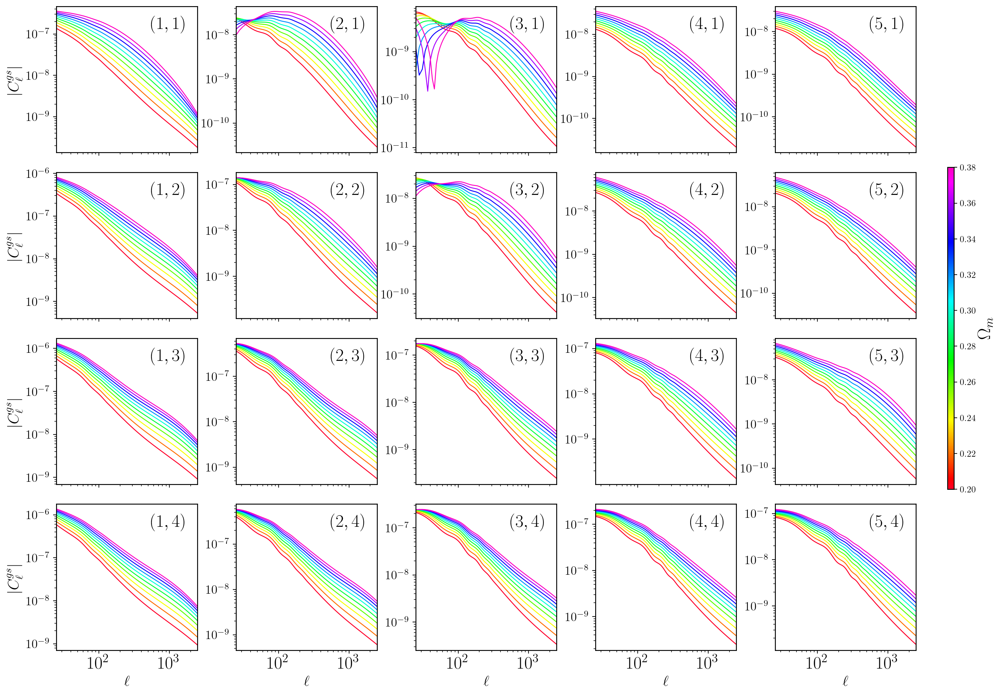

In [16]:
# Absolute mode on logarithmic axes: np.abs keeps a negative C_gs visible.
# Applied to the list, it returns one array [n_param, n_ell, n_lens, n_source].
cnu.plot_C_gs_tomo_limber(ell=ell,
                          C_gs=np.abs(C_gs),
                          param=param,
                          colorbarlabel="$\Omega_m$",
                          bintextpos = [0.8, 0.875],
                          ylim = [0.75,1.3],
                          lmin=ell[0],
                          lmax=ell[len(ell)-1],
                          figsize = (21, 13),
                          bintextsize = 20,
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

In [17]:
ell = np.arange(25., 2500., 3.) # Make sure arange are with float numbers (otherwise there are aliasing problems)
param = np.arange(0.85, 1.1, 0.02)
C_gs = []
for x in param:
    C_gs.append(C_gs_tomo_limber(ell=ell, ns=x))

# Plot the Ratio over ref cosmology
ref = C_gs_tomo_limber(ell=ell)

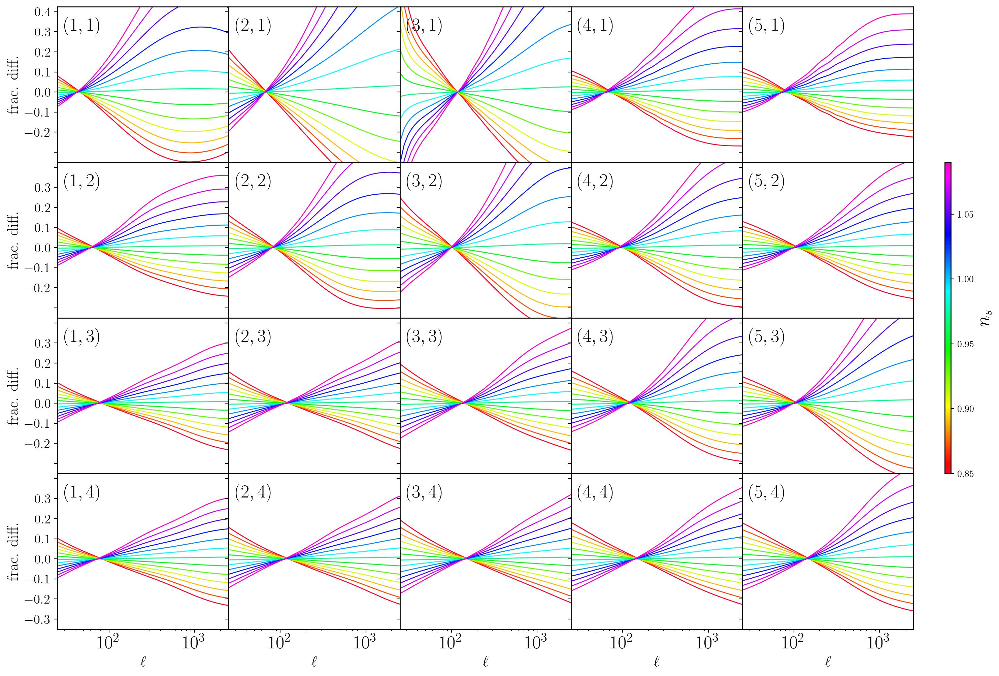

In [18]:
# ylim (0.65, 1.425): the band -35% to +42.5% of C/C_ref - 1
cnu.plot_C_gs_tomo_limber(ell=ell,
                          C_gs=C_gs,
                          C_gs_ref=ref,
                          param=param,
                          colorbarlabel="$n_s$",
                          bintextpos = [0.15, 0.875],
                          ylim = [0.65,1.425],
                          lmin=ell[0],
                          lmax=ell[len(ell)-1],
                          figsize = (20, 12),
                          bintextsize = 20,
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

## How $\Omega_m$ changes $\gamma_t(\theta)$

The *tangential shear* $\gamma_t(\theta)$ is the shear of source galaxies in the
direction tangential to a lens galaxy at angular separation $\theta$, averaged
over all pairs: the real-space counterpart of $C_\ell^{gs}$. The sweep varies
$\Omega_m$ from 0.20 to 0.38; each entry of `gammat_theta` is the pair
`(theta, gammat)` returned by `gamma_t`, and the absolute panels draw $|\gamma_t|$.

In [19]:
param = np.arange(0.2, 0.4, 0.02)   
gammat_theta = []
for x in param:
    # Each entry is the pair (theta, gamma_t)
    gammat_theta.append(gamma_t(omegam = x))

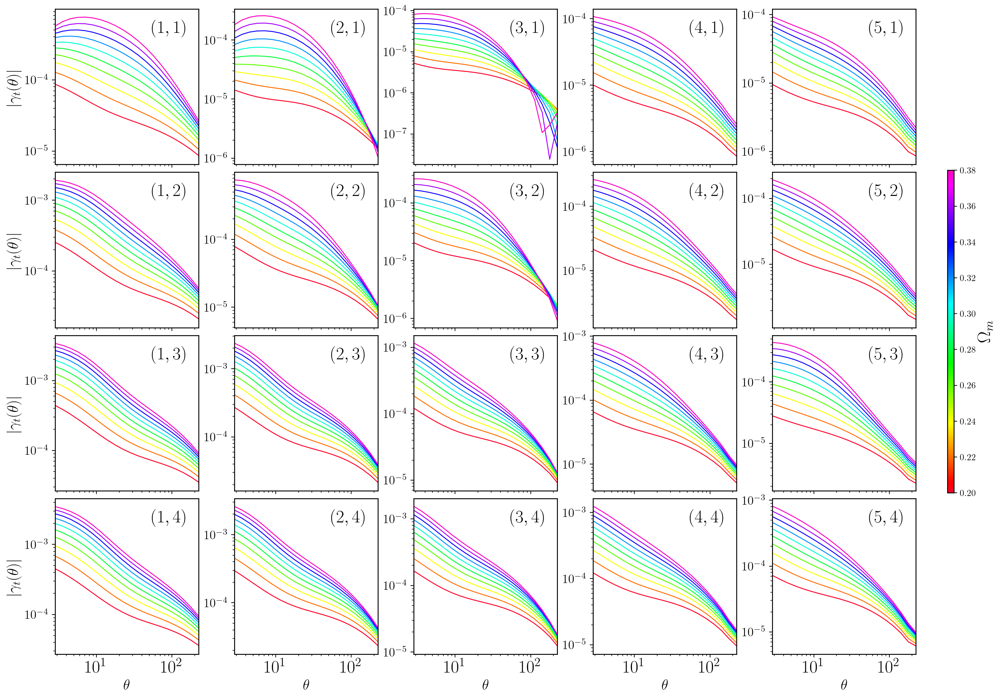

In [20]:
# Absolute mode: |gamma_t| on logarithmic axes; ylim multiplies each
# panel's minimum by 0.75 and its maximum by 1.3
cnu.plot_gammat_tomo_limber(theta_gammat = gammat_theta,
                            gammat_ref = None,
                            param = param,
                            colorbarlabel = "$\Omega_m$",
                            bintextpos = [0.8, 0.875],
                            ylim = [0.75,1.3],
                            figsize = (21, 13),
                            bintextsize = 20,
                            yaxislabelsize = 17,
                            yaxisticklabelsize = 14,
                            xaxisticklabelsize = 20)

## Changing the angular binning without restarting the kernel

The *kernel* is the Python process that runs the cells. CosmoLike keeps
expensive intermediate results, such as the bin-averaged kernels that turn
$C_\ell$ into $\gamma_t(\theta)$, in static arrays: C memory that survives between
calls. Each cached table carries a key; `ci.init_binning` assigns a new key
whenever the number of bins or the angular range changes, so the next call
rebuilds the kernels instead of reusing those of the previous binning.

The cell computes $\gamma_t$ with 9, 12, 17 and 44 bins between 2.5 and 250
arcmin, and the figure marks each binning with its own symbol. The points of all
binnings should follow one smooth curve, wide bins deviating slightly because
each point averages over its bin; a stale cache would instead place the
previous binning's values at the new angles.

In [21]:
nthetas=[9, 12, 17, 44]
gammat_theta = []
for x in nthetas:
    # A new binning on every call: CosmoLike rebuilds its angular kernels
    gammat_theta.append(gamma_t(ntheta=x))

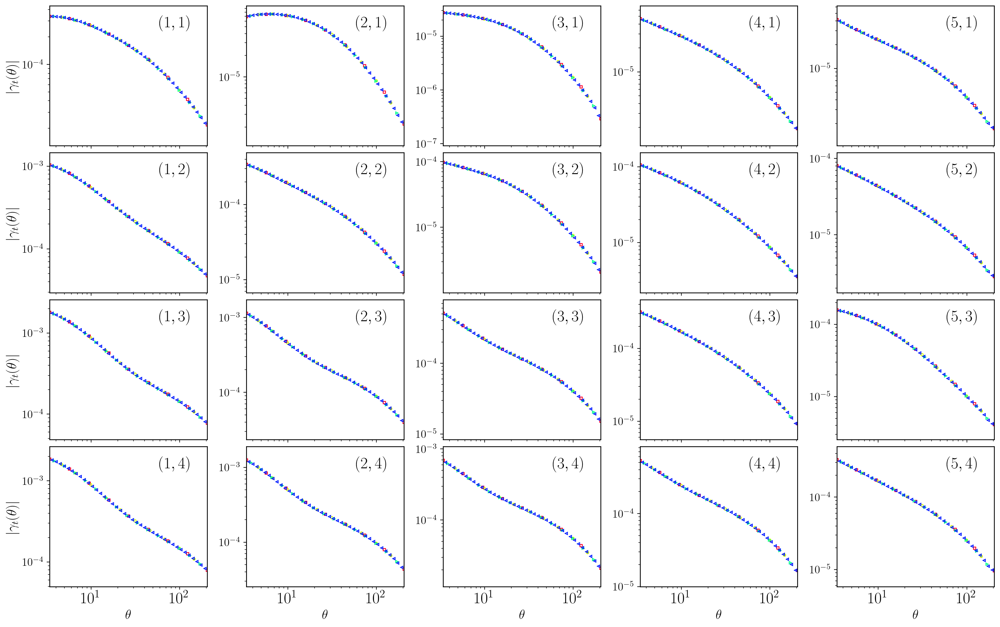

In [22]:
cnu.plot_gammat_tomo_limber(theta_gammat = gammat_theta,
                            marker=['s', 'o', ">", "<"],
                            ylim = [0.75,1.3],
                            bintextpos = [0.8, 0.875],
                            figsize = (21, 13),
                            bintextsize = 20,
                            yaxislabelsize = 17,
                            yaxisticklabelsize = 14,
                            xaxisticklabelsize = 20)

## Baryonic feedback in $C_\ell^{gs}$ and $\gamma_t(\theta)$

Gas physics (cooling, star formation, energy injected by supernovae and active
galactic nuclei) moves matter inside and around halos and changes the matter
power spectrum at small scales. `ci.init_baryons_contamination(sim, allsims)`
multiplies CosmoLike's matter power by the ratio of the power spectrum of one
hydrodynamical simulation to that of its dark-matter-only counterpart, tabulated
in the HDF5 file (a binary table format) `baryons_logPkR.h5` named in the dataset.

The cells compute the nine scenarios listed in `param` and the fiducial without
baryons, then draw each scenario relative to the fiducial, named by a legend
instead of a colorbar. The real-space curves use 40 angular bins, for smoother
lines.

In [23]:
ell = np.arange(3., 7500., 10.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
# Simulation names in the HDF5 table baryons_logPkR.h5
param = ("TNG100-1", "HzAGN-1", "mb2-1", "illustris-1", "eagle-1", "owls_AGN-1", "owls_AGN-2", "owls_AGN-3", "BAHAMAS-2")
    
C_gs = []
for x in param:
    C_gs.append(C_gs_tomo_limber(ell=ell,baryon_sims=x))
    
# Plot the Ratio over ref cosmology
C_gs_ref = C_gs_tomo_limber(ell=ell)

gammat_theta = []
for x in param:
    # 40 angular bins draw smoother curves than the 20 of the data vector
    gammat_theta.append(gamma_t(baryon_sims=x, ntheta=40, AccuracyBoost=1.0))
gammat_theta_ref = gamma_t(ntheta=40, AccuracyBoost=1.0)

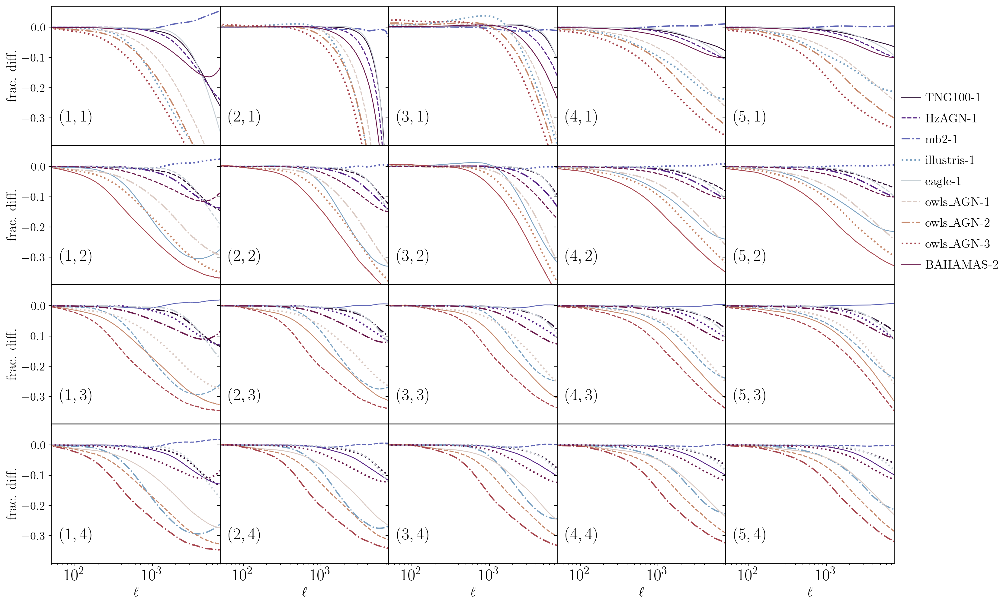

In [24]:
# rcParams are global: every later figure uses this legend font size
matplotlib.rcParams['legend.fontsize'] = 15
# ylim (0.61, 1.07): the band -39% to +7% of C/C_ref - 1
cnu.plot_C_gs_tomo_limber(ell=ell,
                          C_gs=C_gs,
                          C_gs_ref=C_gs_ref,
                          lmin=50,
                          lmax=ell[len(ell)-1],
                          cmap="twilight_shifted",
                          bintextpos = [0.15, 0.2],
                          ylim = [0.61,1.07],
                          legend = param,
                          legendloc=(0.9,0.55),
                          linewidth=[1.0, 1.3, 1.6, 1.9],
                          linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                          figsize = (18, 12),
                          bintextsize = 20,
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

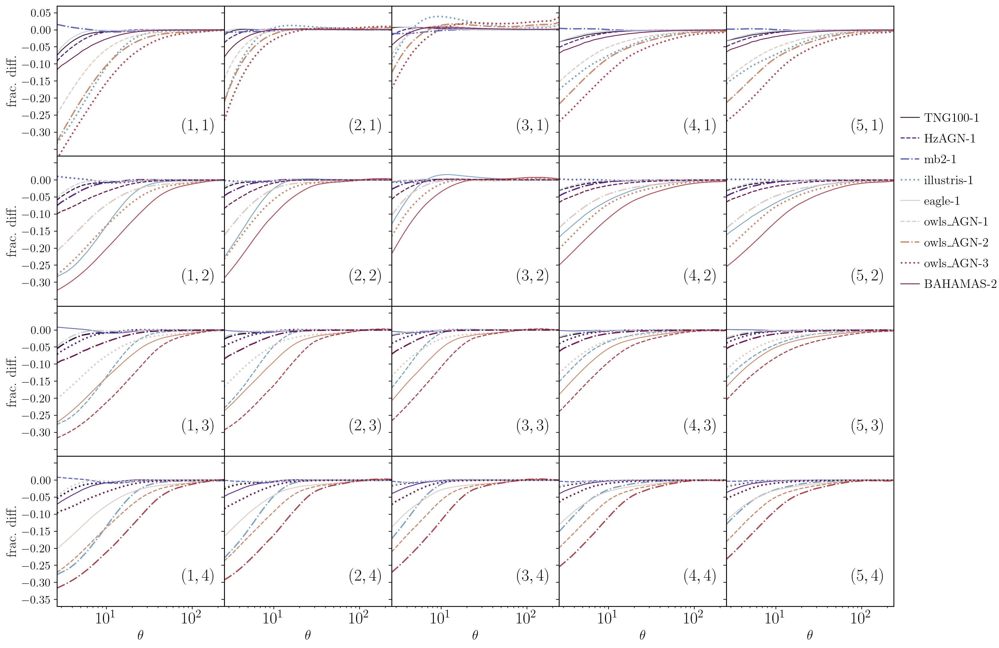

In [25]:
# ylim (0.63, 1.07): the band -37% to +7% of gamma_t/gamma_t,ref - 1
cnu.plot_gammat_tomo_limber(theta_gammat=gammat_theta,
                            gammat_ref=gammat_theta_ref,
                            cmap="twilight_shifted",
                            bintextpos = [0.85, 0.2],
                            ylim = [0.63,1.07],
                            legend = param,
                            legendloc=(0.9,0.55),
                            linewidth=[1.0, 1.3, 1.6, 1.9],
                            linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                            figsize = (18, 13),
                            bintextsize = 20,
                            yaxislabelsize = 17,
                            yaxisticklabelsize = 14,
                            xaxisticklabelsize = 20)

## Accuracy settings: how `AccuracyBoost` changes $C_\ell^{gs}$ and $\gamma_t(\theta)$

`AccuracyBoost` refines three things together: CAMB runs with accuracy
`CAMBAccuracyBoost`$\times(1+(\texttt{AccuracyBoost}-1)/3)$, the CosmoLike tables and
the CAMB grids grow with `AccuracyBoost`, and the wrapper raises the quadrature
level by $|3(\text{boost}-1)|$, rounded down, so a boost below 1 raises it too.

The cell sweeps `AccuracyBoost` from 0.6 to 1.8 in steps of 0.2 and draws each
curve relative to `AccuracyBoost = 1`, on a band of $\pm1.9\%$. The
`C_gs_tomo_limber` defaults are `CAMBAccuracyBoost = 1.0` and
`CLAccuracyBoost = 1.1`, the reverse of the other wrappers, so its
`AccuracyBoost = 1` reference already uses slightly finer CosmoLike tables. The
$\chi^2$ sections below express such differences as $\Delta\chi^2$ against the DES
Y3 covariance.

In [26]:
ell = np.arange(10., 8500., 30.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)

# AccuracyBoost 0.6 to 1.8 refines CAMB, the CosmoLike tables and the
# quadrature level together
param = np.arange(0.6, 2.0, 0.2)

C_gs = []
for x in param:
    C_gs.append(C_gs_tomo_limber(ell=ell,AccuracyBoost=x))
    
# Plot the Ratio over ref cosmology
C_gs_ref = C_gs_tomo_limber(ell=ell)

gammat_theta = []
for x in param:
    gammat_theta.append(gamma_t(ntheta=40, AccuracyBoost=x))
gammat_theta_ref = gamma_t(ntheta=40, AccuracyBoost=1.0)

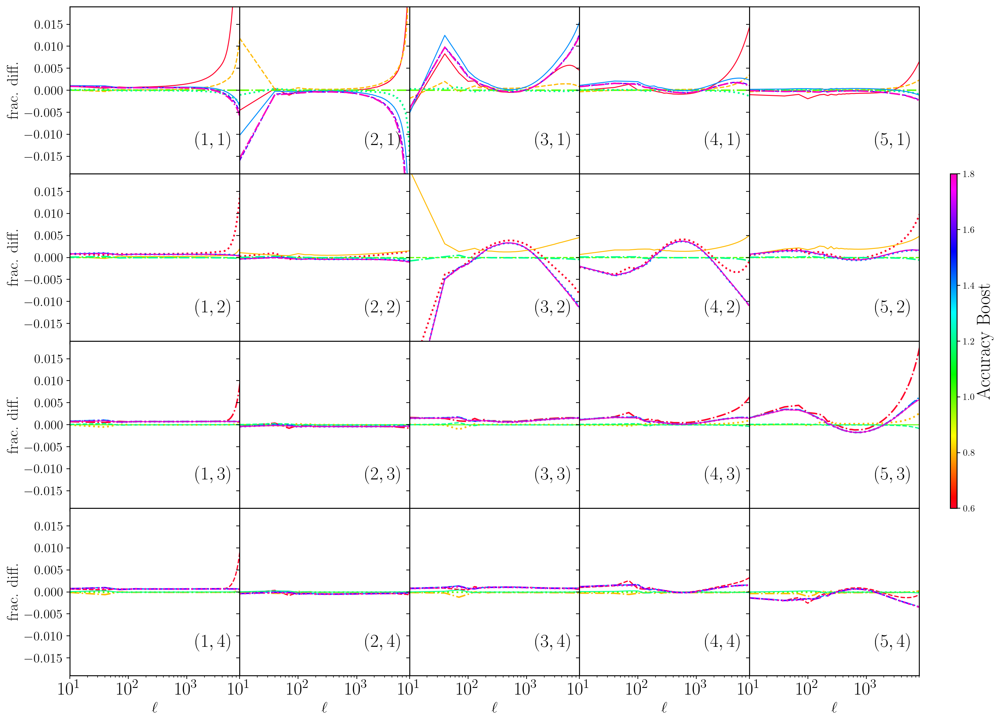

In [27]:
# ylim (0.981, 1.019): the band -1.9% to +1.9% of C/C_ref - 1
cnu.plot_C_gs_tomo_limber(ell=ell,
                          C_gs=C_gs,
                          C_gs_ref=C_gs_ref,
                          param=param,
                          lmin=10,
                          lmax=8000,
                          ylim=(0.981,1.019),
                          bintextpos = [0.85, 0.2],
                          colorbarlabel="Accuracy Boost",
                          linewidth=[1.0, 1.3, 1.6, 1.9],
                          linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                          figsize = (20, 13),
                          bintextsize = 20,
                          yaxislabelsize = 17,
                          yaxisticklabelsize = 14,
                          xaxisticklabelsize = 20)

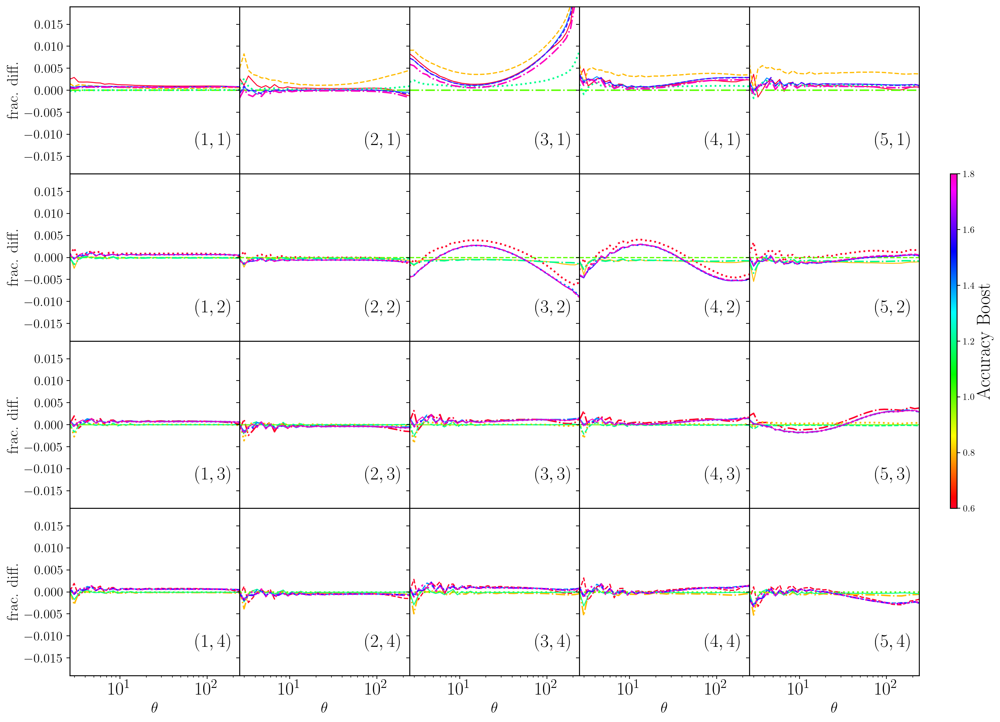

In [28]:
cnu.plot_gammat_tomo_limber(theta_gammat=gammat_theta,
                            gammat_ref=gammat_theta_ref,
                            bintextpos = [0.85, 0.2],
                            ylim = (0.981,1.019),
                            param=param,
                            legendloc=(0.9,0.55),
                            colorbarlabel="Accuracy Boost",
                            linewidth=[1.0, 1.3, 1.6, 1.9],
                            linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                            figsize = (20, 13),
                            bintextsize = 20,
                            yaxislabelsize = 17,
                            yaxisticklabelsize = 14,
                            xaxisticklabelsize = 20)

## How $\Omega_m$ changes $C_\ell^{gg}$, with and without the Limber approximation

`C_gg_tomo(ell, limber=1)` uses the Limber approximation at every multipole;
`limber=0` computes the exact projection, an integral over all wavenumbers with
spherical Bessel functions, below $\ell=150$ and keeps Limber above. The first
cell sweeps $\Omega_m$ from 0.20 to 0.38 for both and draws the absolute spectra,
one panel per lens bin, at 833 multipoles from 3 to 2499. The next cells compute
the ratio non-Limber/Limber at every multipole from 3 to 249 and draw it up to
$\ell=120$: narrow lens bins make the Limber approximation fail at low multipoles.

In [29]:
ell = np.arange(3., 2500., 3.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.2, 0.4, 0.02)
C_gg_L = []
C_gg_NL = []
ratio = []
for x in param:
    # limber=1: Limber at every multipole; limber=0: exact below ell = 150
    tmp1 = C_gg_tomo(ell=ell, limber=1, omegam=x)
    tmp2 = C_gg_tomo(ell=ell, limber=0, omegam=x)
    C_gg_L.append(tmp1)
    C_gg_NL.append(tmp2)

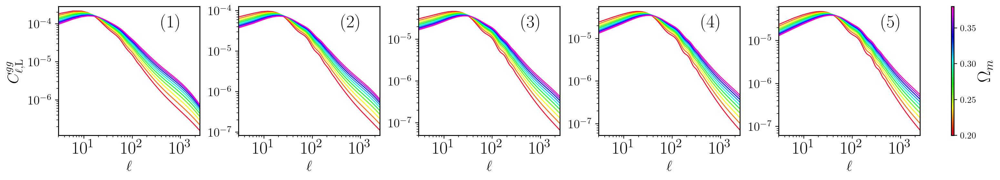

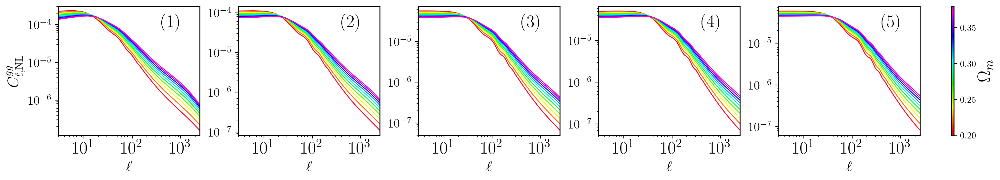

In [30]:
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=C_gg_L,
                   param=param,
                   colorbarlabel="$\Omega_m$",
                   bintextpos = [0.8, 0.875],
                   ylim = [0.75,1.3],
                   lmin=ell[0],
                   lmax=ell[len(ell)-1],
                   overwriteylabel="$C_{\ell,{\\rm L}}^{gg}$",
                   figsize = (21, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=C_gg_NL,
                   param=param,
                   colorbarlabel="$\Omega_m$",
                   bintextpos = [0.8, 0.875],
                   ylim = [0.75,1.3],
                   lmin=ell[0],
                   lmax=ell[len(ell)-1],
                   overwriteylabel="$C_{\ell,{\\rm NL}}^{gg}$",
                   figsize = (21, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)

In [31]:
ell = np.arange(3., 250., 1.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
param = np.arange(0.2, 0.4, 0.02)
ratio = []
for x in param:
    tmp1 = C_gg_tomo(ell=ell, limber=1, omegam=x)
    tmp2 = C_gg_tomo(ell=ell, limber=0, omegam=x)
    # Non-Limber over Limber: equal to 1 from ell = 150 on, where both use Limber
    ratio.append(tmp2/tmp1)

/var/folders/8m/fbnlt6rs00g8g5nshfw27mfw0000gn/T/ipykernel_85951/4259022162.py:8: RuntimeWarning: invalid value encountered in divide
  ratio.append(tmp2/tmp1)


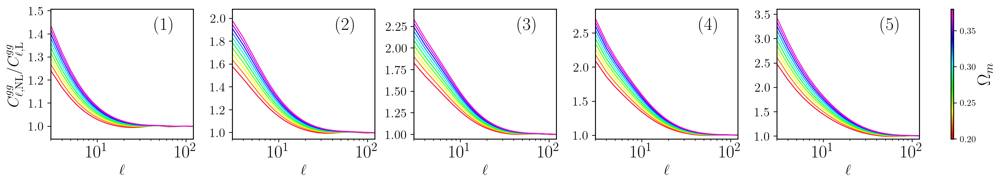

In [32]:
# The ratio itself, drawn in absolute mode on a forced linear axis: ylim
# multiplies its minimum by 0.95 and its maximum by 1.05
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=ratio,
                   param=param,
                   colorbarlabel="$\Omega_m$",
                   bintextpos = [0.8, 0.875],
                   ylim = [0.95,1.05],
                   lmin=3,
                   lmax=120,
                   forcelinearyscale=True,
                   overwriteylabel="$C_{\ell,{\\rm NL}}^{gg}/C_{\ell,{\\rm L}}^{gg}$",
                   forcelinearxscale=False,
                   marker=None,
                   figsize = (21, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)

## How $\Omega_m$ changes $w(\theta)$

The angular correlation function $w(\theta)$ is the excess probability, over a
random distribution, of finding two lens galaxies of the same bin at angular
separation $\theta$: the real-space counterpart of $C_\ell^{gg}$, computed with
the exact projection below $\ell=150$. The sweep varies $\Omega_m$ from 0.20 to
0.38; the absolute panels draw $|w|$, one per lens bin.

In [33]:
param = np.arange(0.2, 0.4, 0.02)   
wtheta_theta = []
for x in param:
    # Each entry is the pair (theta, w)
    wtheta_theta.append(w_theta(omegam = x))

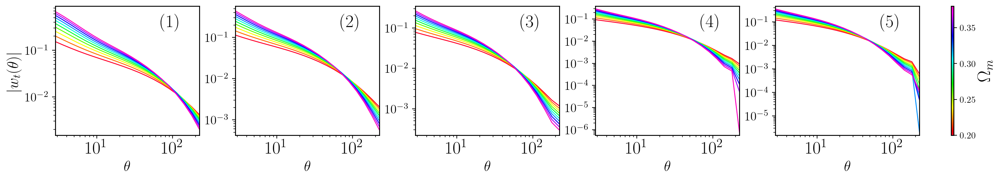

In [34]:
# Absolute mode: |w| on logarithmic axes, one panel per lens bin
cnu.plot_wtheta_tomo(theta_wtheta = wtheta_theta,
                     theta_wtheta_ref = None,
                     param = param,
                     colorbarlabel = "$\Omega_m$",
                     bintextpos = [0.8, 0.875],
                     ylim = [0.75,1.3],
                     figsize = (21, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20)

## Changing the binning of $w(\theta)$ without restarting the kernel

As for $\gamma_t$ above: `ci.init_binning` gives the cached bin-averaged kernels a
new key whenever the binning changes, so the calls with 9, 12, 17 and 44 bins
each rebuild them. The points of all binnings should follow one smooth curve.

In [35]:
nthetas=[9, 12, 17, 44]
wtheta_theta = []
for x in nthetas:
    # A new binning on every call: CosmoLike rebuilds its angular kernels
    wtheta_theta.append(w_theta(ntheta=x))

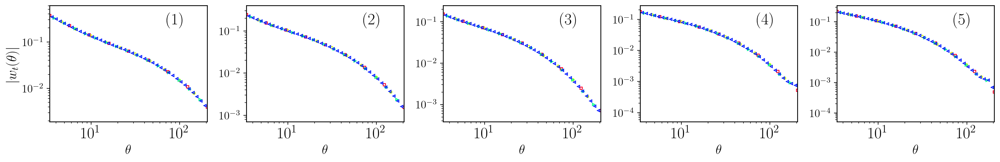

In [36]:
cnu.plot_wtheta_tomo(theta_wtheta=wtheta_theta,
                     marker=['s', 'o', ">", "<"],
                     ylim = [0.75,1.3],
                     bintextpos = [0.8, 0.875],
                     figsize = (21, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20)

## Baryonic feedback in $C_\ell^{gg}$ and $w(\theta)$

The nine hydrodynamical scenarios of the galaxy–galaxy lensing section, now for
clustering. `limber=False` selects the exact projection below $\ell=150$. Each
scenario is drawn relative to the fiducial without baryons.

In [37]:
ell = np.arange(3., 7500., 10.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
# Simulation names in the HDF5 table baryons_logPkR.h5
param = ("TNG100-1", "HzAGN-1", "mb2-1", "illustris-1", "eagle-1", "owls_AGN-1", "owls_AGN-2", "owls_AGN-3", "BAHAMAS-2")
    
C_gg = []
for x in param:
    # limber=False: the exact projection below ell = 150
    C_gg.append(C_gg_tomo(ell=ell,limber=False,baryon_sims=x))
    
# Plot the Ratio over ref cosmology
C_gg_ref = C_gg_tomo(ell=ell,limber=False)

wtheta_theta = []
for x in param:
    # 40 angular bins draw smoother curves than the 20 of the data vector
    wtheta_theta.append(w_theta(baryon_sims=x, ntheta=40, AccuracyBoost=1.0))
wtheta_theta_ref = w_theta(ntheta=40, AccuracyBoost=1.0)

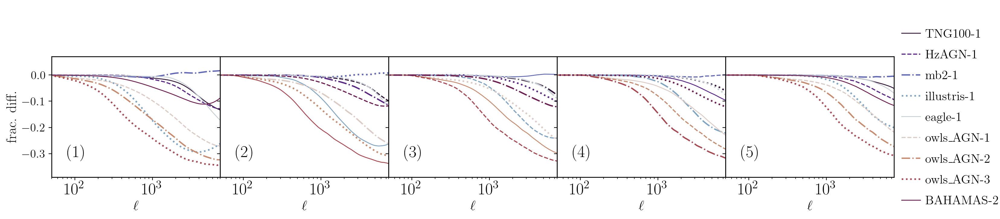

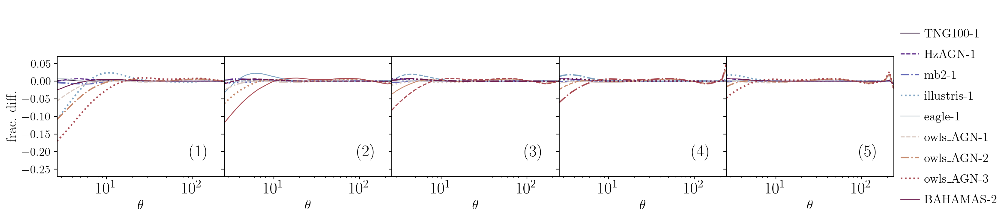

In [38]:
# rcParams are global: every later figure uses this legend font size
matplotlib.rcParams['legend.fontsize'] = 15
# ylim (0.61, 1.07): the band -39% to +7% of C/C_ref - 1
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=C_gg,
                   C_gg_ref=C_gg_ref,
                   lmin=50,
                   lmax=ell[len(ell)-1],
                   cmap="twilight_shifted",
                   bintextpos = [0.15, 0.2],
                   ylim = [0.61,1.07],
                   legend = param,
                   legendloc=(0.9,0.05),
                   linewidth=[1.0, 1.3, 1.6, 1.9],
                   linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                   figsize = (18, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)
# ylim (0.73, 1.07): the band -27% to +7% of w/w_ref - 1
cnu.plot_wtheta_tomo(theta_wtheta=wtheta_theta,
                     theta_wtheta_ref=wtheta_theta_ref,
                     cmap="twilight_shifted",
                     bintextpos = [0.85, 0.2],
                     ylim = [0.73,1.07],
                     legend = param,
                     legendloc=(0.9,0.05),
                     linewidth=[1.0, 1.3, 1.6, 1.9],
                     linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                     figsize = (18, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20)

## Baryonic feedback from the `bfmt` theory block

The two sections *Baryonic feedback in $C_\ell^{gs}$ and $\gamma_t(\theta)$* and
*Baryonic feedback in $C_\ell^{gg}$ and $w(\theta)$* apply fixed simulation ratios:
`ci.init_baryons_contamination` multiplies CosmoLike's matter power by the power
spectrum of one hydrodynamical simulation divided by that of its dark-matter-only
counterpart, as tabulated in the HDF5 file `baryons_logPkR.h5`. This section takes
the other path: the `bfmt` theory block (`external_modules/code/baryon_suppression`)
evaluates parametric models of the suppression
$S(k,z)=P_\mathrm{feedback}(k,z)/P_\mathrm{DMO}(k,z)$, the matter power with baryonic
feedback over the dark-matter-only (DMO) power, at any value of their parameters;
$S<1$ means suppressed power. The block implements seven models:

- three SP(k) relations (Salcido et al. 2023), which map the baryon fraction
  retained in halos, as a function of halo mass and redshift, to $S(k,z)$; they
  differ in how that fraction depends on mass;
- four emulators, fast interpolators trained on suites of simulations and valid
  inside the parameter box they were trained on: BCEmu (a baryonification model),
  the FLAMINGO response emulator, BACCOemu and BCemu2025.

The likelihoods expose both paths: `add_baryons_on_dv` with `which_bsims_add_on_dv`
applies one tabulated simulation, as the two sections above do, and
`external_baryon_suppression: True` requests $S(k,z)$ from `bfmt` on the
likelihood's $(z,k)$ grid and adds $\ln S$ to the nonlinear $\ln P$ table before
`set_cosmology`. Instead of re-implementing the models, this section drives the
block itself through a minimal Cobaya model. Cobaya is the framework in which
Cocoa's likelihoods run, and a *theory block* is a Cobaya component that computes
a product other components request; the model holds CAMB, `bfmt`, and the `one`
likelihood, which always returns zero and only makes Cobaya run the theory
blocks.

The cells below

1. list the six methods run here, each with fixed parameter values (BACCOemu is
   left out, for the reason its comment gives);
2. load the DES Y3 covariance, mask and measured data vector, which $\chi^2$
   needs;
3. define `get_baryon_suppression`, which returns $S(k,z)$, and `compute_probes`,
   which returns $C_\ell^{gs}$, $\gamma_t(\theta)$, the masked 3×2pt data vector and
   its $\chi^2$, with an optional $S$ applied;
4. compute the prediction without feedback and with each method, and print the
   $\chi^2$ table;
5. draw $C_\ell^{gs}$ and $\gamma_t(\theta)$ with each method relative to no feedback.

**Before running.** The section needs `bfmt` and its emulators: the
[baryonic feedback section of the README](README.md#des_y3_baryonic_feedback)
lists the installation keys that must stay commented out. It runs CAMB 13 times,
once for the prediction without feedback and twice per method (in the Cobaya
model and in `compute_probes`), a few minutes in total.

In [39]:
# One entry per feedback method: (label, bfmt options, fixed parameter
# point). The SP(k) points are pyspk's documented examples; the emulator
# points are the fiducial values quoted in the example yamls. BACCOemu
# is commented out on this project: its omega_baryon training box
# starts at 0.04001, exactly above this notebook's omegab = 0.04, so
# the block (correctly) rejects the fiducial.
BARYON_METHODS = [
    ("SP(k) power law", {"baryon_model": 1, "spk_fb_model": 1},
     {"fb_a_spk": 0.4, "fb_pow_spk": 0.3}),
    ("SP(k) Akino et al. 2022", {"baryon_model": 1, "spk_fb_model": 2},
     {"alpha_spk": 4.189, "beta_spk": 1.273, "gamma_spk": 0.298}),
    # this point matches the Akino relation's amplitude at the pivot
    # and stays inside SP(k)'s calibrated baryon-fraction band over
    # the full z grid; pyspk's documented example (0.3, 1.1, 0.2,
    # 0.5) exits the band at z >~ 1.4, and the block then falls back
    # to unity for those redshifts
    ("SP(k) double power law", {"baryon_model": 1, "spk_fb_model": 3},
     {"epsilon_spk": 0.66, "alpha_spk": 0.35, "beta_spk": 0.2,
      "gamma_spk": 0.3}),
    ("BCEmu", {"baryon_model": 2},
     {"log10Mc_bcemu": 13.32, "mu_bcemu": 0.93, "thej_bcemu": 4.235,
      "gamma_bcemu": 2.25, "delta_bcemu": 6.40, "eta_bcemu": 0.15,
      "deta_bcemu": 0.14}),
    ("Flamingo", {"baryon_model": 3},
     {"fgas_sigma_flamingo": 0.0, "mstar_sigma_flamingo": 0.0,
      "jet_frac_flamingo": 0.0}),
    #("BACCOemu", {"baryon_model": 4},
    # {"M_c_baccoemu": 14.0, "eta_baccoemu": -0.3, "beta_baccoemu": -0.22,
    #  "M1_z0_cen_baccoemu": 10.5, "theta_inn_baccoemu": -0.86}),
    ("BCemu2025", {"baryon_model": 5},
     {"Theta_co_bcemu25": 0.3, "log10Mc_bcemu25": 13.1, "mu_bcemu25": 1.0,
      "delta_bcemu25": 6.0, "eta_bcemu25": 0.10, "deta_bcemu25": 0.22,
      "Nstar_bcemu25": 0.028}),
]

**The data of $\chi^2$.** The initialization cell near the top of the notebook
does not load the covariance, the mask or the measured data vector. The next cell
loads them with the sequence of the $\chi^2$ section at the end of the notebook:
`initial_setup` resets every CosmoLike setting, and the cell sets again the
FAST-PT grid fraction, the probes (all three, so the 533 baseline entries enter
$\chi^2$), the 20 angular bins of the data vector, the nonlinear run mode, the IA
model and the $n(z)$ tables, before `init_data_real` reads the three files named
in `des_y3_real.dataset`. The reset comes first because `init_data_real` adds the
data-vector length to the length CosmoLike holds, so a rerun without it would
double that length. Every setting the wrappers above read is either set again at
each wrapper call or restored here to the value of the initialization cell, so
the cells after this section compute what they computed before.

In [40]:
# initial_setup first: init_data_real adds the data-vector length to the
# length CosmoLike holds, so without the reset a rerun of this cell would
# double it. The rest repeats the sequence of the chi^2 section at the end
# of the notebook; ini is the dataset file read by the initialization cell.
ci.initial_setup()

# initial_setup resets the FAST-PT grid fraction to the C default; set it
# again before compute_probes calls init_accuracy_boost
ci.init_fpt_internal_boost(internal_boost = float(internal_accuracyboost))

# 3x2pt: all 533 baseline entries keep their mask
ci.init_probes(possible_probes = CLprobe)

# The binning of the data vector, 20 logarithmic bins from 2.5 to 250
# arcmin: init_data_real sizes the data vector from it, so it comes first
ci.init_binning(ntheta_bins = int(ini.int("n_theta")),
                theta_min_arcmin = ini.float("theta_min_arcmin"),
                theta_max_arcmin = ini.float("theta_max_arcmin"))

# False: use the nonlinear matter power spectrum
ci.init_cosmo_runmode(is_linear = False)

ci.init_IA(ia_model = int(IA_model),
           ia_redshift_evolution = int(IA_redshift_evolution),
           ia_code = int(IA_code))

ci.init_redshift_distributions_from_files(
      lens_multihisto_file = ini.relativeFileName('nz_lens_file'),
      lens_ntomo = int(ini.int("lens_ntomo")),
      source_multihisto_file = ini.relativeFileName('nz_source_file'),
      source_ntomo = int(ini.int("source_ntomo")))

# The published DES Y3 covariance, the 3x2pt baseline mask and the
# measured data vector named in the dataset file
ci.init_data_real(COV = ini.relativeFileName('cov_file'),
                  MASK = ini.relativeFileName('mask_file'),
                  DATA = ini.relativeFileName('data_file'))

**The two functions.**

- `get_baryon_suppression(theory_options, point, z_grid, log10k_grid)` builds the
  minimal Cobaya model, evaluates it at the notebook's fiducial cosmology plus the
  method's parameters, and returns a dictionary `{z: S}` with one array over the
  requested wavenumbers per redshift. Each call runs CAMB once.
- `compute_probes(sup=None)` runs the five stages of the wrappers at the fiducial
  point. Between CAMB and `set_cosmology`, when `sup` is given, it adds
  $\ln S(k,z)$ to a copy of the nonlinear $\ln P$ table, the operation the
  likelihoods apply. It returns a dictionary with $C_\ell^{gs}$ at the multipoles
  `ell`, $\gamma_t$ at the angles `theta` (arcmin) of the 20 data-vector bins, the
  masked data vector `dv`, its `chi2`, and the grids `z_grid` and `log10k_grid` of
  the CAMB tables.

Both read the fiducial values from the notebook at every call and take no
cosmology arguments, so a suppression and the prediction it multiplies always
share one cosmology. `compute_probes` uses the accuracy settings of `get_chi2` at
its default arguments (the $\chi^2$ section below): CAMB at accuracy 1.1 with
$k_\mathrm{max}=10$/Mpc and 20 samples per logarithmic interval, CosmoLike tables at
boost 1 and quadrature level 0, the level of `EXAMPLE_EVALUATE2.yaml` (the $\chi^2$
section prints level 1). They stay fixed because another boost changes the
$(z,k)$ grid, and $S$ must be given on the grid it multiplies.

**Units at the handoff.** `cnu.get_camb_cosmology` returns $\log_{10}k$ with $k$ in
$h$/Mpc, the unit of `set_cosmology`, while `get_baryon_suppression`, like the
likelihoods' request to `bfmt`, reads $k$ in 1/Mpc. The `log10k_grid` that
`compute_probes` returns is therefore $\log_{10}k+\log_{10}h$, with $h=H_0/100$ for
$H_0$ in km/s/Mpc: the same nodes, in 1/Mpc. The $h$/Mpc grid handed over unchanged
would evaluate $S$ at $k/h$, about $1.49\,k$ at $h=0.6732$, instead of at $k$.

In [41]:
def get_baryon_suppression(theory_options, point, z_grid, log10k_grid):
    """Return the suppression S(k, z) of the bfmt theory block on a grid.

    S = P(k) with baryonic feedback / P(k) without it. Builds a minimal
    Cobaya model (CAMB + bfmt + the likelihood "one", which returns
    ln L = 0 and only makes the model complete), requests the
    baryon_suppression product at the given grid (k in 1/Mpc, as the
    Cosmolike likelihoods send it; the block converts to h/Mpc
    internally), evaluates it at the notebook's fiducial cosmology (the
    names of the "Fiducial parameters" cell, read at every call), and
    returns {z: S array over k}.

    Arguments:
      theory_options = bfmt options dict, e.g. {"baryon_model": 2}.
      point   = {parameter name: value} for the method's feedback
                parameters, fixed in the model.
      z_grid  = redshifts of the evaluation grid.
      log10k_grid = log10 of the wavenumbers, read as k in 1/Mpc.

    Returns:
      {z: 1D S array over k}, one entry per z_grid value.
    """
    from cobaya.model import get_model
    # Cobaya model description: CAMB at the notebook's fiducial
    # cosmology (tau = 0.0543, a Planck 2018 value, only completes
    # CAMB's input; omch2 subtracts the massive-neutrino density),
    # bfmt with the caller's options and feedback parameters, and
    # debug = 50 (logging.CRITICAL: only critical messages print)
    info = {
        "likelihood": {"one": None},
        "theory": {
            # no "path" for camb: the session already imported it,
            # and cobaya accepts the loaded module as is
            "camb": {"extra_args": {"halofit_version": "takahashi",
                                    "dark_energy_model": "ppf"}},
            "bfmt": dict({"python_path": os.environ["ROOTDIR"]
                          + "/external_modules/code/baryon_suppression"},
                         **theory_options),
        },
        "params": dict({
            "As": {"value": As_1e9*1e-9},
            "ns": ns, "H0": H0, "mnu": mnu, "tau": 0.0543,
            "w": w,
            "ombh2": omegab*(H0/100)**2,
            "omch2": (omegam-omegab)*(H0/100)**2
                     - (mnu*(3.046/3)**0.75)/94.0708,
            "omegam": {"derived": True, "latex": r"\Omega_m"},
        }, **point),
        "debug": 50,
    }
    model = get_model(info)
    model.add_requirements({"baryon_suppression": {
        "z": z_grid, "k": np.power(10.0, log10k_grid)}})
    # every parameter is fixed, so the point to evaluate is the empty
    # dictionary; the call runs CAMB and bfmt once
    model.logposterior({})
    return model.provider.get_baryon_suppression()

In [42]:
def compute_probes(sup = None, ell = None):
    """Compute C_ell^gs, gamma_t, the masked 3x2pt data vector and its chi^2.

    Runs the five stages of the wrappers at the fiducial point of the
    "Fiducial parameters" cell, whose names are read from the notebook at
    every call, as get_baryon_suppression reads them: a suppression and the
    prediction it multiplies share one cosmology. The run settings, the
    photo-z conventions and ini (the dataset file, which fixes the
    data-vector binning) are read from the notebook as well. sup = None
    computes the dark-matter-only prediction; otherwise sup is the
    {z: S array} dictionary of get_baryon_suppression, applied the way the
    likelihoods apply it: ln P_nonlinear(k, z_i) += ln S(k, z_i) at every
    redshift node z_i. The accuracy settings are the defaults of get_chi2
    (the chi^2 section at the end of the notebook), fixed here because a
    different boost changes the (z, k) grid on which sup must be given.

    Arguments:
      sup = suppression dictionary on the CAMB interpolation grid (one
            entry per z of z_grid, each an array over the k of
            log10k_grid), or None.
      ell = multipoles of the returned C_ell^gs, or None for
            np.arange(25, 3000, 15), the multipole range of the figure.

    Returns:
      dict with
        ell         = the multipoles, [n_ell];
        C_gs        = Limber C_ell^gs, [n_ell, n_lens, n_source], plain
                      dimensionless spectra;
        theta       = area-weighted centers of the data-vector angular
                      bins, [n_theta], in arcmin;
        gammat      = gamma_t, [n_theta, n_lens, n_source];
        dv          = the masked data vector: all 900 entries, masked
                      ones set to zero;
        chi2        = (d - t)^T C^-1 (d - t) over the retained entries,
                      with d the measured DES Y3 data vector;
        z_grid      = the redshift nodes of the CAMB tables;
        log10k_grid = log10 of the wavenumber nodes, k in 1/Mpc, the unit
                      get_baryon_suppression takes.

    Raises:
      RuntimeError when no data vector is loaded: compute_chi2 would
      otherwise stop the whole Python process.
    """
    # the data cell of this section loads the mask; without it the mask is
    # empty, and the chi^2 call below would end the kernel, not raise
    n_mask = len(ci.get_mask())
    if n_mask == 0:
        raise RuntimeError(
            "compute_probes: CosmoLike holds no data vector (its mask has "
            "0 entries); the chi^2 needs the DES Y3 covariance, mask and "
            "data vector: run the data cell of this section first")

    if ell is None:
        ell = np.arange(25., 3000., 15.)

    # Stage 1, CAMB, with the defaults of get_chi2: accuracy 1.1,
    # kmax = 10/Mpc and 20 samples per logarithmic interval in k
    # (lnPL_cb is not used)
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth,
     z_interp_1D, chi, omegan2, lnPL_cb) = cnu.get_camb_cosmology(
        omegam = omegam, omegab = omegab, H0 = H0, ns = ns,
        As_1e9 = As_1e9, w = w, w0pwa = w0pwa, mnu = mnu,
        non_linear_emul = non_linear_emul, AccuracyBoost = 1.0,
        kmax = 10, k_per_logint = 20, CAMBAccuracyBoost = 1.1,
        CLAccuracyBoost = 1.0)

    # a private copy of ln P_nonlinear, modified in place below
    lnPNL = np.array(lnPNL, copy = True)
    if sup is not None:
        for i, z_val in enumerate(z_interp_2D):
            # every k of redshift node i sits at stride len(z_interp_2D)
            # in the flattened (Fortran-order) table, the layout
            # set_cosmology expects. sup[z_val] looks the redshift up by
            # exact float equality, which holds because sup was computed
            # on this same z grid (the z_grid returned below).
            lnPNL[i :: len(z_interp_2D)] += np.log(sup[z_val])

    # Stage 2, accuracy and model settings of the C code: tables at boost
    # 1, whose largest tabulated multipole is 50,000, and quadrature level
    # 0, the defaults of get_chi2
    ci.init_ntable_lmax(lmax = 50000)
    ci.init_photoz_conventions(
        interpolation_type = int(photoz_interpolation_type),
        zmid_convention = int(photoz_zmid_convention))
    # init_fpt_internal_boost comes first, as in the likelihood, so the
    # FAST-PT grid fraction is the configured one even when this is the
    # first init_accuracy_boost of the process
    ci.init_fpt_internal_boost(internal_boost = float(internal_accuracyboost))
    ci.init_accuracy_boost(accuracy_boost = 1.0, integration_accuracy = 0)
    # the binning of the loaded data vector: the gamma_t and w_theta
    # wrappers may have left another one
    ci.init_binning(ntheta_bins = int(ini.int("n_theta")),
                    theta_min_arcmin = ini.float("theta_min_arcmin"),
                    theta_max_arcmin = ini.float("theta_max_arcmin"))
    # Codes for (b1, b2, bs2, b3, bmag), as in the wrappers: 0 = one
    # amplitude per lens bin; 1 for b3 = derived from b1 as b1 - 1
    ci.init_bias(bias_model = [0, 0, 0, 1, 0])

    # Stage 3: copy the CAMB tables, with S applied, into CosmoLike
    ci.set_cosmology(omegam = omegam,
                     H0 = H0,
                     log10k_2D = log10k_interp_2D,
                     z_2D = z_interp_2D,
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)

    # Stage 4, nuisance parameters at the fiducial point: source side (the
    # IA setter reads A1[0:2], A2[0:2] and B_TA[0]; zeros pad the lists),
    # lens side, then the point masses of gamma_t
    ci.set_nuisance_shear_calib(M = [DES_M1, DES_M2, DES_M3, DES_M4])
    ci.set_nuisance_shear_photoz(
        bias = [DES_DZ_S1, DES_DZ_S2, DES_DZ_S3, DES_DZ_S4])
    ci.set_nuisance_ia(A1 = [DES_A1_1, DES_A1_2, 0, 0, 0],
                       A2 = [DES_A2_1, DES_A2_2, 0, 0, 0],
                       B_TA = [DES_BTA_1, 0, 0, 0, 0])
    ci.set_nuisance_clustering_photoz(
        bias = [DES_DZ_L1, DES_DZ_L2, DES_DZ_L3, DES_DZ_L4, DES_DZ_L5])
    ci.set_nuisance_bias(
        B1 = [DES_B1_1, DES_B1_2, DES_B1_3, DES_B1_4, DES_B1_5],
        B2 = [0, 0, 0, 0, 0],
        B_MAG = [DES_BMAG_1, DES_BMAG_2, DES_BMAG_3, DES_BMAG_4, DES_BMAG_5],
        B3nl = [0, 0, 0, 0, 0],
        BK = [0, 0, 0, 0, 0])
    ci.set_point_mass(PMV = [DES_PM_1, DES_PM_2, DES_PM_3, DES_PM_4, DES_PM_5])
    # S, when given, already sits in lnPNL: the tabulated simulation ratio
    # of init_baryons_contamination stays off
    ci.reset_bary_struct()

    # Stage 5: the spectra, the masked data vector and its chi^2, then
    # gamma_t at the data-vector binning
    C_gs = ci.C_gs_tomo_limber(l = ell)
    dv = np.array(ci.compute_data_vector_masked())
    chi2 = ci.compute_chi2(datavector = dv)
    theta = ci.get_binning_real_space()
    gammat = ci.w_gammat_tomo()
    return {"ell": ell,
            "C_gs": C_gs,
            "theta": theta,
            "gammat": gammat,
            "dv": dv,
            "chi2": chi2,
            "z_grid": z_interp_2D,
            # get_baryon_suppression takes k in 1/Mpc, but the CAMB helper
            # returns this grid in h/Mpc: convert here, at the one place
            # that links the two, so S(k) is evaluated at the physical k.
            "log10k_grid": log10k_interp_2D + np.log10(H0/100.0)}

**Without and with feedback.** The first cell computes the prediction without
feedback and prints its $\chi^2$ against the measured DES Y3 data vector, the
number of entries that enter $\chi^2$ (533) and the length of the masked data
vector (900: the masked entries are zero). The measurements scatter around any
model, and the fiducial point is not a fit to them, so this $\chi^2$ is far from
zero, unlike a $\chi^2$ against a synthetic data vector computed at the same point.

The second cell loops over the six methods: for each it computes $S(k,z)$ on the
$(z,k)$ grid of the CAMB tables, then the prediction with that suppression, and
prints its $\chi^2$. The third cell prints the table, one row per prediction, no
feedback first:

- $\chi^2$ against the measured data vector, over the 533 retained entries;
- $\Delta\chi^2=\chi^2-\chi^2_\mathrm{none}$, the change from the prediction without
  feedback, of either sign: feedback can move the prediction toward the
  measurements or away from them;
- the $\chi^2$ of the shift, $(t-t_\mathrm{none})^{\mathsf T}C^{-1}(t-t_\mathrm{none})$, with
  $t$ the masked prediction and $C$ the DES Y3 covariance: the distance between the
  predictions with and without feedback in units of the measurement errors,
  independent of the measured values. A value well above one means that the
  baseline scale cuts do not protect a DES Y3 analysis from feedback of that
  strength.

In [43]:
# ref holds ell, C_gs, theta, gammat, the masked data vector dv, its chi2,
# and the z and log10 k grids of the CAMB tables
ref = compute_probes()
# get_mask returns the 0/1 flag of every data-vector entry: their sum is
# the number of entries that enter chi^2
n_retained = int(np.sum(ci.get_mask()))
print("no feedback: chi2 = %.4f over %d data points, data vector length = %d" %
      (ref["chi2"], n_retained, len(ref["dv"])))

no feedback: chi2 = 1369.0434 over 533 data points, data vector length = 900


In [44]:
# For each method: one Cobaya model (CAMB + bfmt) gives S(k, z) on the grid
# of ref, then one data vector with S applied to the nonlinear power.
# ref["log10k_grid"] is already in 1/Mpc, the unit get_baryon_suppression
# takes.
results = {}
for label, theory_options, point in BARYON_METHODS:
    sup = get_baryon_suppression(theory_options = theory_options,
                                 point = point,
                                 z_grid = ref["z_grid"],
                                 log10k_grid = ref["log10k_grid"])
    results[label] = compute_probes(sup = sup)
    # flush = True prints each line as soon as its method is done
    print("%-28s chi2 = %10.4f" % (label, results[label]["chi2"]),
          flush = True)

SP(k) power law              chi2 =  1356.6868


SP(k) Akino et al. 2022      chi2 =  1359.4934


SP(k) double power law       chi2 =  1359.4953


BCEmu                        chi2 =  1360.1730


Flamingo                     chi2 =  1363.9668


Loading BCemu2025 models (backend='numpy')...


Loading model weights:   0%|          | 0/21 [00:00<?, ?it/s]

...BCemu2025 emulator is ready.


BCemu2025                    chi2 =  1370.7979


In [45]:
# C^-1 as CosmoLike holds it: a 900 x 900 matrix whose masked rows and
# columns are zero, the matrix compute_chi2 contracts, so the difference of
# two masked data vectors can be contracted with it directly
inv_cov = np.array(ci.get_inv_cov_masked())

# the label of every (label, bfmt options, point) entry, in table order
labels = [label for label, _, _ in BARYON_METHODS]

print("chi2 over %d data points (the DES Y3 3x2pt baseline mask)" % n_retained)
print("%-28s %12s %12s %14s" % ("method", "chi2", "Delta chi2", "chi2 of shift"))
# the no-feedback row first, then one row per method
rows = [("no feedback", ref)]
for label in labels:
    rows.append((label, results[label]))
for label, result in rows:
    delta_chi2 = result["chi2"] - ref["chi2"]
    # (t - t_none)^T C^-1 (t - t_none); @ is the matrix product
    shift = result["dv"] - ref["dv"]
    chi2_shift = shift @ inv_cov @ shift
    print("%-28s %12.4f %12.4f %14.4f" %
          (label, result["chi2"], delta_chi2, chi2_shift))

chi2 over 533 data points (the DES Y3 3x2pt baseline mask)
method                               chi2   Delta chi2  chi2 of shift
no feedback                     1369.0434       0.0000         0.0000
SP(k) power law                 1356.6868     -12.3566         0.8073
SP(k) Akino et al. 2022         1359.4934      -9.5500         0.3101
SP(k) double power law          1359.4953      -9.5481         0.3085
BCEmu                           1360.1730      -8.8704         0.3580
Flamingo                        1363.9668      -5.0766         0.0593
BCemu2025                       1370.7979       1.7545         0.0165


**$C_\ell^{gs}$ with feedback.** One row per source bin and one column per lens
bin, labeled (lens, source), with $C_\ell^{gs,\,\mathrm{feedback}}/C_\ell^{gs,\,\mathrm{none}}-1$
for $25\le\ell<3000$, one color per method: the colorbar values only order the
methods, the legend above the panels names them, and the two lightest colors are
drawn dashed. The first cell defines
`fitted_ratio_band`, which fits the band to the curves: from the lowest to the
highest drawn value, zero included, plus 10% of that width at each end. Expect no
change at low $\ell$ and a suppression that grows with $\ell$. Pairs whose source
bin lies in front of the lens bin carry little lensing signal, so their ratios say
little about feedback.

In [46]:
def fitted_ratio_band(curves, reference):
    """Return a band (lower, upper) fitted to every curve/reference - 1.

    The band spans the smallest and the largest value of
    curve/reference - 1 over all curves and panels, includes 0 (the
    no-feedback line), and adds 10% of its width at each end, so the
    curves fill the panels without touching the frame. Panels whose
    reference is identically zero (pairs excluded from the data vector)
    are skipped, as the plotters skip them.

    Arguments:
      curves    = list of arrays [n_x, n_lens, n_source], one per method;
                  n_x counts multipoles or angular bins.
      reference = the no-feedback array, with the same shape.

    Returns:
      (1 + low - padding, 1 + high + padding): the band written around 1,
      the ylim convention of the cnu plotters with a reference.
    """
    low = 0.0
    high = 0.0
    n_lens = reference.shape[1]
    n_source = reference.shape[2]
    for curve in curves:
        for i in range(n_lens):
            for j in range(n_source):
                if not np.any(reference[:, i, j]):
                    continue
                ratio = curve[:, i, j]/reference[:, i, j] - 1
                low = min(low, np.min(ratio))
                high = max(high, np.max(ratio))
    padding = 0.1*(high - low)
    return (1 + low - padding, 1 + high + padding)

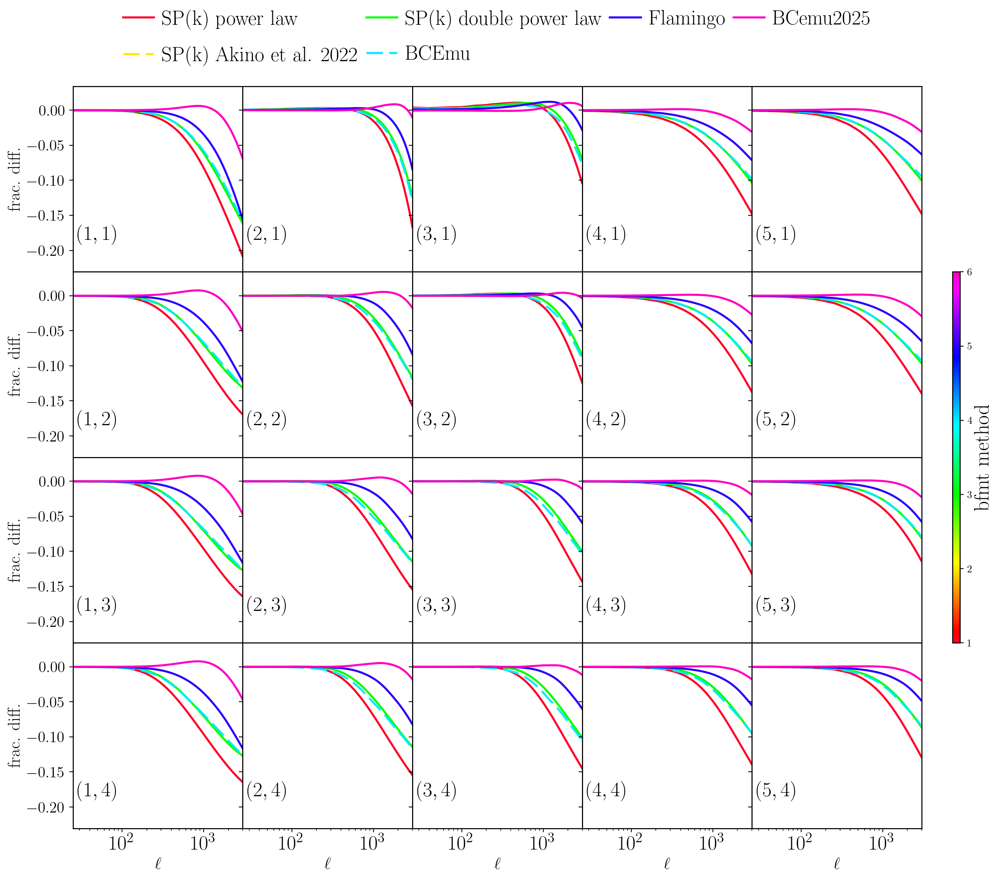

In [47]:
# param only orders the curve colors, one value per method; the legend
# above the panels names the methods
param = np.arange(1.0, 1.0 + len(labels))

# One linestyle per method, in BARYON_METHODS order, so every panel draws
# a method with the same style: the colormap gives the second method a
# light yellow and the fourth a light cyan, which get a long dash
# ((0, (8, 3)): 8 points drawn, 3 skipped); a wide line (linewidth, one
# entry repeated for every curve) keeps all six curves visible
method_linestyles = ["solid", (0, (8, 3)), "solid", (0, (8, 3)), "solid", "solid"]
if len(method_linestyles) != len(labels):
    raise ValueError(
        "method_linestyles has %d entries for %d methods in BARYON_METHODS: "
        "give one linestyle per method" % (len(method_linestyles), len(labels)))

C_gs_list = []
for label in labels:
    C_gs_list.append(results[label]["C_gs"])

C_gs_band = fitted_ratio_band(curves = C_gs_list, reference = ref["C_gs"])

# bintextpos (0.15, 0.2): the lower-left corner of each panel, which the
# curves leave free (they sit at zero at low ell)
cnu.plot_C_gs_tomo_limber(ell = ref["ell"],
                          C_gs = C_gs_list,
                          C_gs_ref = ref["C_gs"],
                          param = param,
                          colorbarlabel = "bfmt method",
                          lmin = 25,
                          lmax = 3000,
                          ylim = C_gs_band,
                          legend = labels,
                          linestyle = method_linestyles,
                          linewidth = [2.0],
                          bintextpos = [0.15, 0.2],
                          bintextsize = 20,
                          figsize = (18, 13),
                          legendfontsize = 20,
                          xaxisticklabelsize = 20,
                          yaxisticklabelsize = 15,
                          yaxislabelsize = 17)

**$\gamma_t(\theta)$ with feedback.** The same grid in real space,
$\gamma_t^\mathrm{feedback}/\gamma_t^\mathrm{none}-1$ at the 20 angular bins of the data
vector, from 2.5 to 250 arcmin. Each row of panels (one source bin) gets its own
band, fitted to its curves as for $C_\ell^{gs}$. Expect the suppression to
concentrate at small angles, where $\gamma_t$ probes the matter distribution close
to the lens halos.

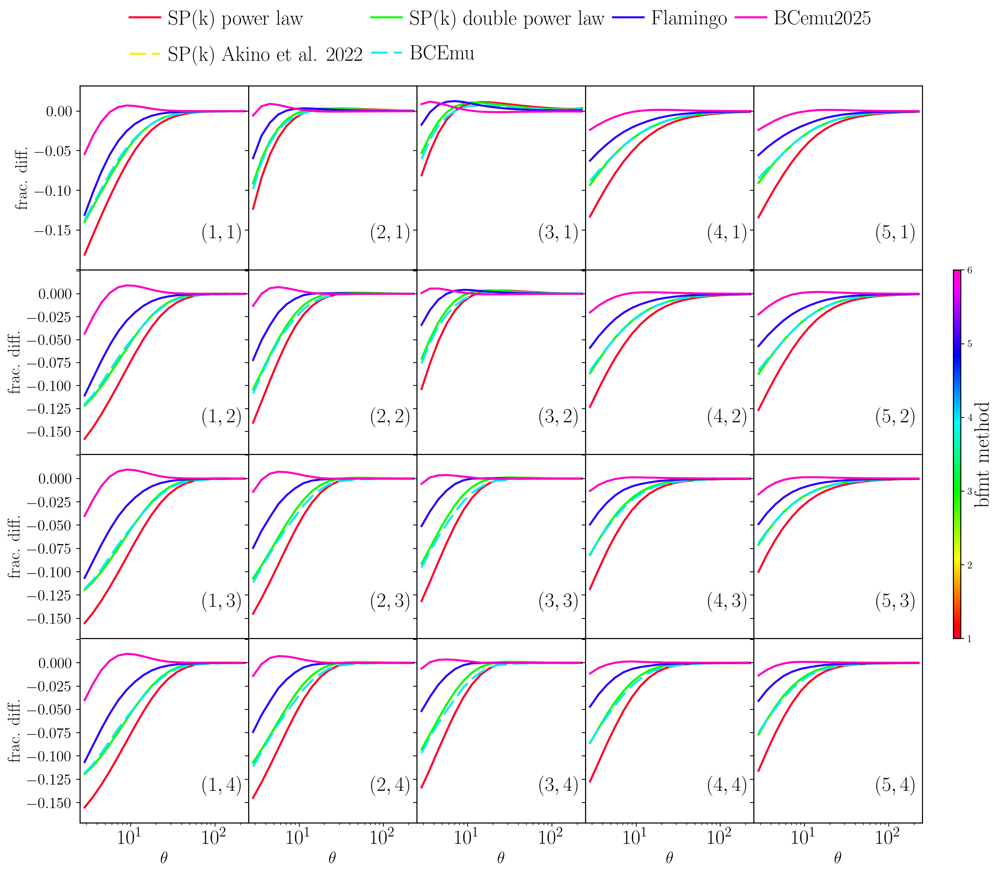

In [48]:
# Each entry is the (theta, gammat) pair that plot_gammat_tomo_limber expects
gammat_list = []
for label in labels:
    gammat_list.append((results[label]["theta"], results[label]["gammat"]))
gammat_ref = (ref["theta"], ref["gammat"])

# One fitted band per source row: the slice [:, :, j:j+1] keeps source bin
# j as an axis of length 1, the shape fitted_ratio_band reads
gammat_row_bands = []
for j in range(ref["gammat"].shape[2]):
    row_curves = []
    for label in labels:
        row_curves.append(results[label]["gammat"][:, :, j:j+1])
    row_band = fitted_ratio_band(curves = row_curves,
                                 reference = ref["gammat"][:, :, j:j+1])
    gammat_row_bands.append(row_band)

# bintextpos (0.85, 0.2): the lower-right corner of each panel, which the
# curves leave free (they approach zero at large angles)
cnu.plot_gammat_tomo_limber(theta_gammat = gammat_list,
                            gammat_ref = gammat_ref,
                            param = param,
                            colorbarlabel = "bfmt method",
                            ylim = gammat_row_bands,
                            thetashow = [2.5, 250],
                            legend = labels,
                            linestyle = method_linestyles,
                            linewidth = [2.0],
                            bintextpos = [0.85, 0.2],
                            bintextsize = 20,
                            figsize = (18, 13),
                            legendfontsize = 20,
                            xaxisticklabelsize = 20,
                            yaxisticklabelsize = 15,
                            yaxislabelsize = 17)

## Accuracy settings: how `AccuracyBoost` changes $C_\ell^{gg}$ and $w(\theta)$

The same sweep as for galaxy–galaxy lensing, `AccuracyBoost` from 0.6 to 1.8,
for $C_\ell^{gg}$ with the exact projection below $\ell=150$ and for $w(\theta)$, each
curve drawn relative to `AccuracyBoost = 1`: on a band of $\pm1.5\%$ for the
spectra and $\pm10\%$ for $w(\theta)$.

In [49]:
# Accuracy-boost check of C_ell^gg and w(theta): the sweep follows in the
# next cell, the ratio figures in the cell after it.

In [50]:
ell = np.arange(10., 8500., 30.) # Make sure np.arange are set w/ float numbers (otherwise there are aliasing problems)
# AccuracyBoost 0.6 to 1.8; C_gg with the exact projection below ell = 150
param = np.arange(0.6, 2.0, 0.2)

C_gg = []
for x in param:
    C_gg.append(C_gg_tomo(ell=ell,limber=False,AccuracyBoost=x))
    
# Plot the Ratio over ref cosmology
C_gg_ref = C_gg_tomo(ell=ell,limber=False)

wtheta_theta = []
for x in param:
    wtheta_theta.append(w_theta(ntheta=40, AccuracyBoost=x))
wtheta_theta_ref = w_theta(ntheta=40, AccuracyBoost=1.0)

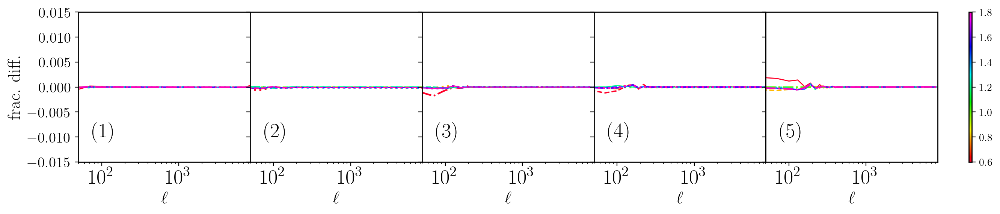

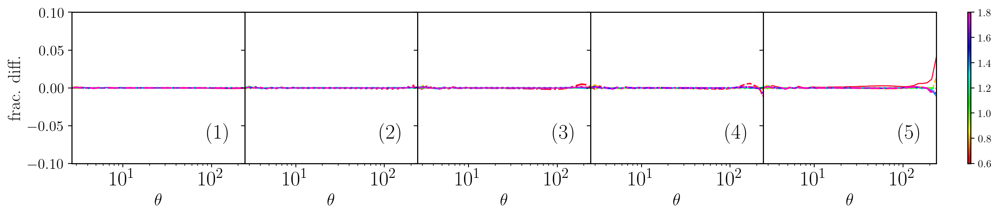

In [51]:
matplotlib.rcParams['legend.fontsize'] = 15
# ylim (0.985, 1.015): the band -1.5% to +1.5% of C/C_ref - 1
cnu.plot_C_gg_tomo(ell=ell,
                   C_gg=C_gg,
                   C_gg_ref=C_gg_ref,
                   lmin=50,
                   lmax=ell[len(ell)-1],
                   bintextpos = [0.15, 0.2],
                   ylim = [0.985,1.015],
                   param = param,
                   legendloc=(0.9,0.05),
                   linewidth=[1.0, 1.3, 1.6, 1.9],
                   linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                   figsize = (18, 13./5),
                   bintextsize = 20,
                   yaxislabelsize = 17,
                   yaxisticklabelsize = 14,
                   xaxisticklabelsize = 20)
# ylim (0.9, 1.1): the band -10% to +10% of w/w_ref - 1
cnu.plot_wtheta_tomo(theta_wtheta=wtheta_theta,
                     theta_wtheta_ref=wtheta_theta_ref,
                     bintextpos = [0.85, 0.2],
                     ylim = [0.9,1.1],
                     param = param,
                     legendloc=(0.9,0.05),
                     linewidth=[1.0, 1.3, 1.6, 1.9],
                     linestyle = ['solid', 'dashed', 'dashdot', 'dotted'],
                     figsize = (18, 13./5),
                     bintextsize = 20,
                     yaxislabelsize = 17,
                     yaxisticklabelsize = 14,
                     xaxisticklabelsize = 20)

## $\chi^2$ against the DES Y3 3×2pt data

The next cell initializes CosmoLike again, now with data. `init_probes("3x2pt")`
keeps all three probes, so the 533 baseline entries enter $\chi^2$;
`init_data_real` reads the published DES Y3 covariance, the 3×2pt baseline mask
and the measured data vector named in the dataset file, and `init_bias` selects
the bias model of the wrappers.

`get_chi2` runs CAMB and every setter, then

- `compute_data_vector_masked()` returns all 900 entries, masked ones set to
  zero;
- `compute_chi2(t)` returns $\chi^2=(d-t)^{\mathsf T}C^{-1}(d-t)$ over the retained
  entries only, with $C^{-1}$ the inverse of the retained block of the covariance.

**Comparison with `EXAMPLE_EVALUATE2.yaml`.** The model settings match that file
(TATT with power-law evolution, Halofit, the bias model, `lmax` 50,000), but three
inputs differ, so the printed $\chi^2$ is not the YAML's value: `DES_A2_1 = -1.79`
here and 0.01 there; quadrature level 1 in the print cell and
`integration_accuracy: 0` there; and CAMB with `kmax = 10`/Mpc,
`k_per_logint = 20` and accuracy 1.1 here, where the YAML uses 5, 10 and 1.0.

In [52]:
non_linear_emul = 2
CLprobe="3x2pt"

path= "../../external_modules/data/des_y3"
data_file="des_y3_real.dataset"

IA_model = 1
IA_redshift_evolution = 3
IA_code = 0

ini = IniFile(os.path.normpath(os.path.join(path, data_file)))

ci.initial_setup()

# initial_setup resets the FAST-PT grid fraction to the C default;
# set it again before get_chi2 calls init_accuracy_boost
ci.init_fpt_internal_boost(internal_boost = float(internal_accuracyboost))

# 3x2pt: all 533 baseline entries keep their mask
ci.init_probes(possible_probes = CLprobe)

ci.init_binning(int(ini.int("n_theta")), 
                ini.float("theta_min_arcmin"), 
                ini.float("theta_max_arcmin"))

ci.init_cosmo_runmode(is_linear = False)

ci.init_IA( ia_model = int(IA_model), 
            ia_redshift_evolution = int(IA_redshift_evolution),
            ia_code = int(IA_code))

ci.init_redshift_distributions_from_files(
      lens_multihisto_file=ini.relativeFileName('nz_lens_file'),
      lens_ntomo=int(ini.int("lens_ntomo")), 
      source_multihisto_file=ini.relativeFileName('nz_source_file'),
      source_ntomo=int(ini.int("source_ntomo")))

# The published DES Y3 covariance, the 3x2pt baseline mask and the
# measured data vector named in the dataset file
ci.init_data_real(ini.relativeFileName('cov_file'), 
                  ini.relativeFileName('mask_file'), 
                  ini.relativeFileName('data_file'))

# The bias codes of the wrappers: (b1, b2, bs2, b3, bmag), b3 from b1
if CLprobe != "xi":
    ci.init_bias(bias_model=[0,0,0,1,0])

def get_chi2(omegam = omegam, 
             omegab = omegab, 
             H0 = H0, 
             ns = ns, 
             As_1e9 = As_1e9, 
             w = w, 
             w0pwa = w0pwa,
             A1  = [DES_A1_1, DES_A1_2, 0, 0, 0], 
             A2  = [DES_A2_1, DES_A2_2, 0, 0, 0],
             BTA = [DES_BTA_1, 0, 0, 0, 0],
             shear_photoz_bias = [DES_DZ_S1, DES_DZ_S2, DES_DZ_S3, DES_DZ_S4],
             M = [DES_M1, DES_M2, DES_M3, DES_M4],
             lens_photoz_bias = [DES_DZ_L1, DES_DZ_L2, DES_DZ_L3, DES_DZ_L4, DES_DZ_L5],
             galaxy_bias_b1 = [DES_B1_1, DES_B1_2, DES_B1_3, DES_B1_4, DES_B1_5],
             galaxy_bias_b2 = [0,0,0,0,0],
             galaxy_bias_bmag = [DES_BMAG_1,DES_BMAG_2,DES_BMAG_3,DES_BMAG_4,DES_BMAG_5],
             PM = [DES_PM_1, DES_PM_2, DES_PM_3, DES_PM_4, DES_PM_5],
             baryon_sims = None,
             AccuracyBoost=1.0, 
             kmax = 10, 
             k_per_logint = 20, 
             CAMBAccuracyBoost=1.1,
             CLAccuracyBoost=1.0, 
             CLIntegrationAccuracy = 0):

    CLAccuracyBoost = CLAccuracyBoost * AccuracyBoost
    CLIntegrationAccuracy = max(0, CLIntegrationAccuracy + abs(3*(CLAccuracyBoost-1.0)))

    ci.init_ntable_lmax(int(50000 + 20000*(CLAccuracyBoost-1)))
    ci.init_accuracy_boost(CLAccuracyBoost, int(CLIntegrationAccuracy))
    ci.init_photoz_conventions(
        int(photoz_interpolation_type),
        int(photoz_zmid_convention))
    
    # CAMB. CLAccuracyBoost already includes AccuracyBoost, and
    # get_camb_cosmology multiplies the two again, so its grids would see
    # AccuracyBoost squared: the calls below keep AccuracyBoost = 1.
    (log10k_interp_2D, z_interp_2D, lnPL, lnPNL, G_growth, z_growth, z_interp_1D, chi,
     omegan2, lnPL_cb) = cnu.get_camb_cosmology(omegam=omegam, 
        omegab=omegab, H0=H0, ns=ns, As_1e9=As_1e9, w=w, w0pwa=w0pwa, mnu=mnu, non_linear_emul=non_linear_emul,
            AccuracyBoost=AccuracyBoost, kmax=kmax,
        k_per_logint=k_per_logint, CAMBAccuracyBoost=CAMBAccuracyBoost,
        CLAccuracyBoost=CLAccuracyBoost)
    
    ci.set_cosmology(omegam = omegam, 
                     H0 = H0, 
                     log10k_2D = log10k_interp_2D, 
                     z_2D = z_interp_2D, 
                     lnP_linear = lnPL,
                     lnP_nonlinear = lnPNL,
                     G = G_growth,
                     z_G = z_growth,
                     z_1D = z_interp_1D,
                     chi = chi,
                     omegan2 = omegan2)

    ci.set_nuisance_bias(B1=galaxy_bias_b1,
                         B2=galaxy_bias_b2,
                         B_MAG=galaxy_bias_bmag,
                         B3nl=[0,0,0,0,0],
                         BK=[0,0,0,0,0])

    ci.set_nuisance_clustering_photoz(bias=lens_photoz_bias)

    ci.set_point_mass(PMV=PM)
    
    ci.set_nuisance_shear_calib(M=M)

    ci.set_nuisance_shear_photoz(bias=shear_photoz_bias)

    ci.set_nuisance_ia(A1 = A1, 
                       A2 = A2, 
                       B_TA = BTA)

    # All 900 entries, masked ones set to zero; compute_chi2 forms
    # (d - t)^T C^-1 (d - t) over the retained entries only
    datavector = np.array(ci.compute_data_vector_masked())
    return ci.compute_chi2(datavector)

In [53]:
# Quadrature level 1, while EXAMPLE_EVALUATE2.yaml uses level 0; DES_A2_1
# and the CAMB settings differ too (see the markdown above)
print(rf"$\chi^2$={get_chi2(CLIntegrationAccuracy = 1):3.3f}")

$\chi^2$=1369.769


## Quadrature check: $\Delta\chi^2$ against the integration level

The next cell evaluates the 3×2pt $\chi^2$ at quadrature levels 0 to 9, everything
else fixed, and subtracts the level-0 value; the plot after it shows
$\Delta\chi^2$ against the level (the figure has no axis labels). Each level
selects a fixed Gauss–Legendre rule, a set of points and weights for the
line-of-sight integrals, from 64 to 128 points at level 0, depending on the
probe, up to 1024. From level 4 on every probe uses its 1024-point rule, so the
curve is flat there. The project's tests treat $|\Delta\chi^2|<0.2$ as
numerically negligible.

In [54]:
param = np.arange(0, 10, 1)      
chi2 = []
for x in param:
    chi2.append(get_chi2(CLIntegrationAccuracy = x))
chi2 = np.array(chi2)
# Delta chi^2 relative to quadrature level 0
chi2 = chi2 - chi2[0]

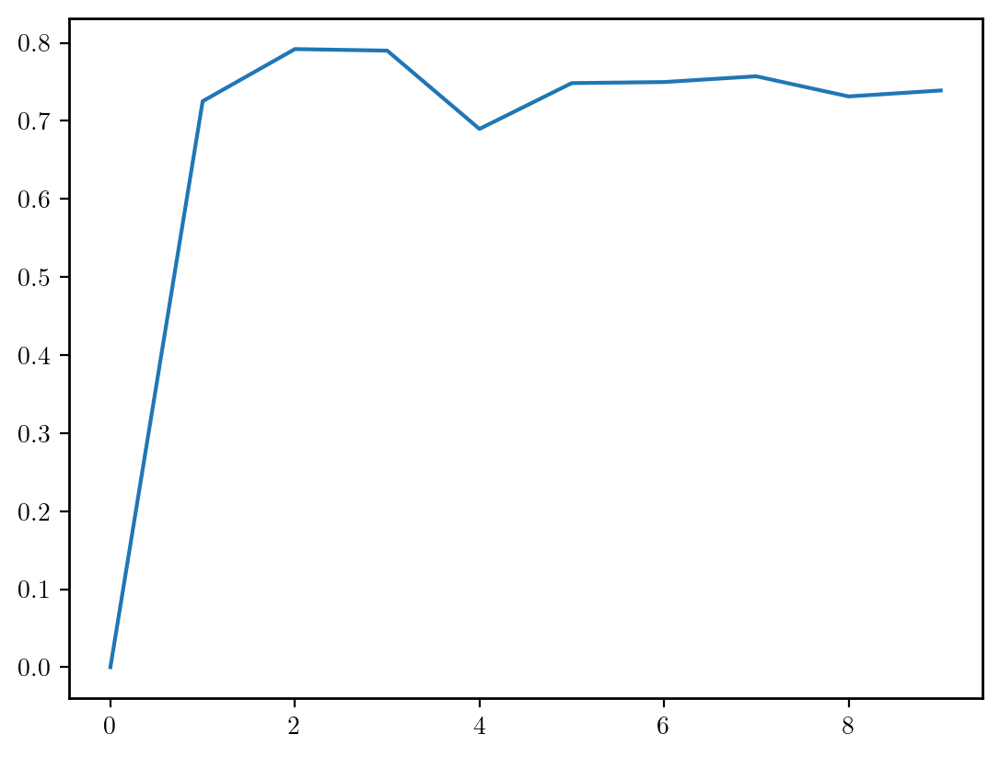

In [55]:
# Horizontal: quadrature level; vertical: Delta chi^2 (no axis labels)
plt.plot(param, np.array(chi2))

## Interpolation check: $\Delta\chi^2$ against `CLAccuracyBoost`

The next cell evaluates $\chi^2$ at `CLAccuracyBoost` = 1, 2, ..., 9 and
subtracts the boost-1 value. This boost multiplies the sizes of CosmoLike's
interpolation tables and the redshift and wavenumber grids of the CAMB tables,
and raises the multipole cutoff of `init_ntable_lmax` by 20,000 per unit;
CAMB's own accuracy stays fixed. Although the call passes
`CLIntegrationAccuracy = 1`, `get_chi2` raises the quadrature level to
$1+3(\text{boost}-1)$, so this scan refines interpolation and quadrature
together; from boost 2 on, the quadrature already uses its largest rule. The
plot has no axis labels: horizontal is the boost, vertical $\Delta\chi^2$.

In [56]:
param = np.arange(1, 10, 1)      
chi2 = []
for x in param:
    chi2.append(get_chi2(CLAccuracyBoost=x, CLIntegrationAccuracy = 1))
chi2 = np.array(chi2)
# Delta chi^2 relative to CLAccuracyBoost = 1; the quadrature level is
# 1 + 3 (boost - 1), so it rises with the boost
chi2 = chi2 - chi2[0]

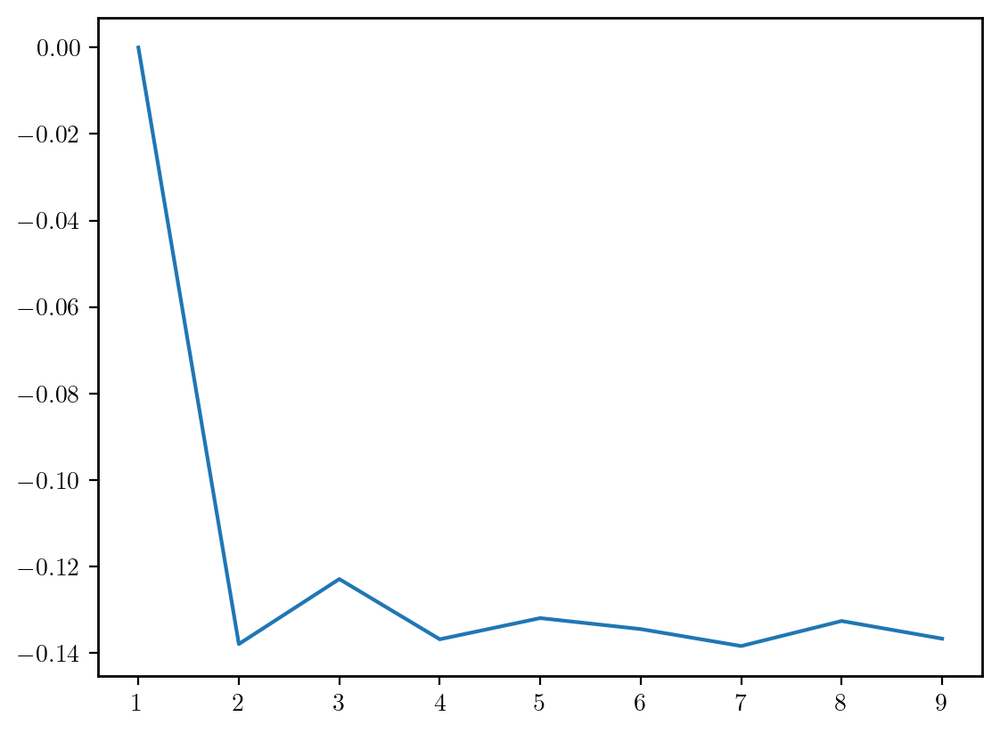

In [57]:
# Horizontal: CLAccuracyBoost; vertical: Delta chi^2 (no axis labels)
plt.plot(param, np.array(chi2))

<!-- DRAFT: Fable rewrites -->
## A 3×2pt Fisher forecast

The Fisher matrix $F=D^{\mathsf T}C^{-1}D$ of the masked 3×2pt data vector (533 of
the 900 entries, the DES Y3 baseline mask, with the published covariance), at
the notebook's base accuracy (`AccuracyBoost` = 1) and relative step $h=0.025$
(five-point stencil, absolute step for $w_a$, whose fiducial is 0). Column $p$
of $D$ is the derivative of the data vector with respect to parameter $p$.

**Parameters.** The 30 entries of `nw.FISHER_3X2PT_PARAM_NAMES`: $10^9A_s$,
$n_s$, $H_0$, $\Omega_b$, $\Omega_m$, $w_0$, $w_a$ (0–6), the five TATT parameters
(7–11), the four source photo-z shifts (12–15), the four shear calibrations
(16–19), the five lens photo-z shifts (20–24) and the five linear galaxy biases
(25–29): every parameter `EXAMPLE_EVALUATE2.yaml` samples except $\sum m_\nu$,
fixed at 0.06 eV. The magnification biases and the point masses stay at their
fixed YAML values. Gaussian priors from `likelihood/params_source.yaml` and
`likelihood/params_lens.yaml`: source photo-z 0.018, 0.015, 0.011, 0.017; shear
calibration 0.009, 0.008, 0.008, 0.008; lens photo-z 0.004, 0.003, 0.003,
0.005, 0.01. The fiducial is the notebook's, with $w_0=-0.9$, $w_a=0$ free.

Four data vectors per parameter, 120 for the matrix. The FoMs of $(w_0,w_a)$ and
$(10^9A_s,\Omega_m)$ are printed, and the triangle shows the cosmological
parameters with every nuisance parameter marginalized.

In [58]:
# nw: this project's notebook wrappers (projects/des_y3/interface). The
# cells above keep their own helpers; this section uses nw.
import time
import cosmolike_des_y3_notebook_wrappers as nw
print('Using notebook wrappers installed at %s' % (nw.__file__))

# The derivatives difference the data vector between nearby cosmologies;
# the caution about CAMB's halofit tolerance in EXAMPLE_EVALUATE1.ipynb
# (Fisher section) applies here too.
ini = nw.init_cosmolike(CLprobe="3x2pt", with_data=True)
param = nw.fisher_3x2pt_fiducial_point()
param_names = nw.FISHER_3X2PT_PARAM_NAMES
param_labels = nw.FISHER_3X2PT_PARAM_LABELS
flat_priors = nw.FISHER_FLAT_PRIORS
# C^-1 as CosmoLike holds it: masked rows and columns are zero
invcov = np.array(ci.get_inv_cov_masked())
iw0 = param_names.index("w0")
iwa = param_names.index("wa")
iAs = param_names.index("As_1e9")
iOm = param_names.index("omegam")
sel = [0, 1, 2, 3, 4, 5, 6]

t0 = time.perf_counter()
F_base = nw.get_Fisher_3x2pt(CV=param, h=0.025, AccuracyBoost=1.0)
seconds_base = time.perf_counter() - t0
base_label = "h = 0.025, AccuracyBoost = 1"
print(f"{4*len(param)} data vectors in {seconds_base:.0f} s; "
      f"{int(np.sum(np.diag(invcov) != 0))} data points enter F")
print(f"FoM(w0, wa)            = {cnu.get_FoM(iw0, iwa, F_base):.4g}")
print(f"FoM(10^9 A_s, Omega_m) = {cnu.get_FoM(iAs, iOm, F_base):.4g}")
cov_base = np.linalg.inv(0.5*(F_base + F_base.T))
for k in sel:
    print(f"  sigma({param_names[k]:>6s}) = {np.sqrt(cov_base[k, k]):10.4g}"
          f"   (fiducial {param[k]:.5g})")

Using notebook wrappers installed at /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/projects/des_y3/interface/cosmolike_des_y3_notebook_wrappers.py


120 data vectors in 135 s; 533 data points enter F
FoM(w0, wa)            = 1.254
FoM(10^9 A_s, Omega_m) = 23.23
  sigma(As_1e9) =     0.9906   (fiducial 2.1)
  sigma(    ns) =    0.09258   (fiducial 0.96605)
  sigma(    H0) =       16.1   (fiducial 67.32)
  sigma(omegab) =    0.01986   (fiducial 0.04)
  sigma(omegam) =    0.05275   (fiducial 0.3)
  sigma(    w0) =     0.9126   (fiducial -0.9)
  sigma(    wa) =      3.824   (fiducial 0)


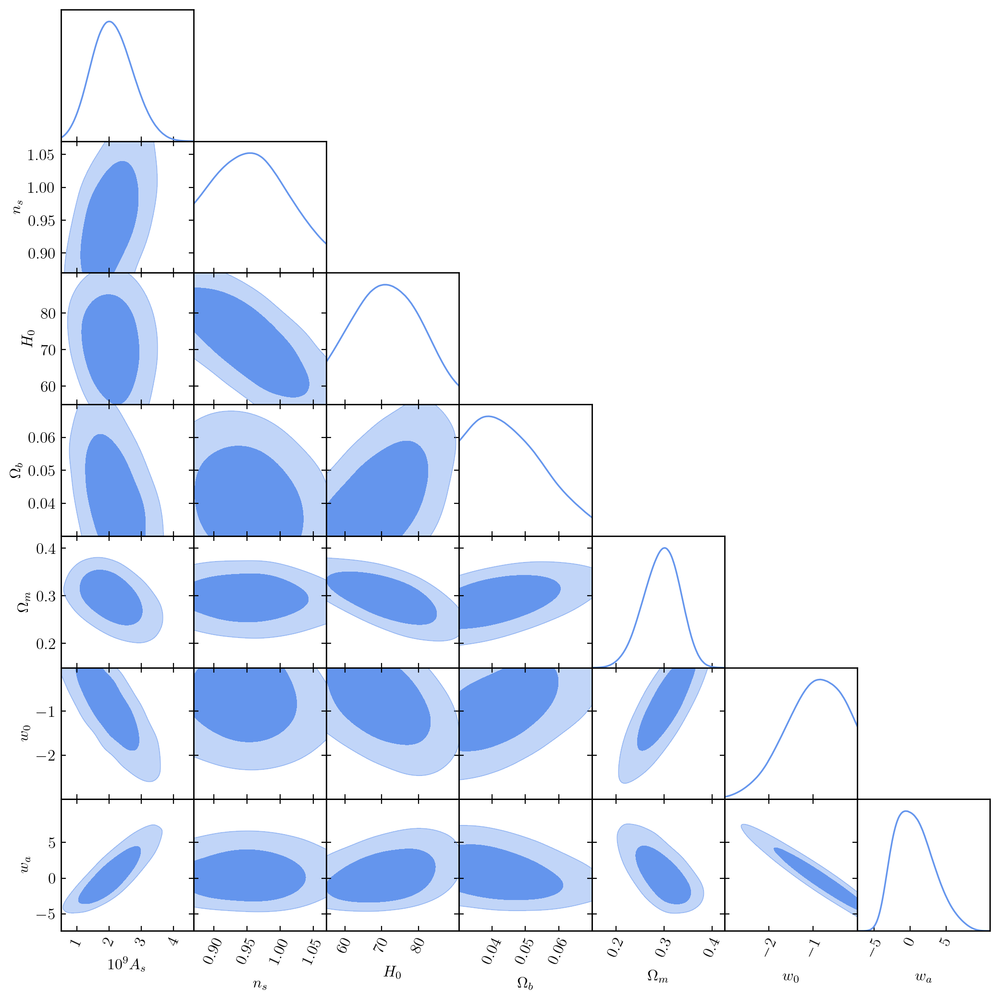

In [59]:
# contours of the seven cosmological parameters, the 23 nuisance
# parameters marginalized; the samples are clipped to the flat priors
g = nw.plot_Fisher(F=F_base,
                   mu=param,
                   select=sel,
                   labels=param_labels,
                   names=param_names,
                   filled=True,
                   flat_priors=flat_priors)

### How numerical noise moves the dark-energy figure of merit

A computed data vector is the smooth model plus a small numerical
error: the integration grids, the distance grids and CAMB's tolerances
leave a remnant that changes irregularly from one parameter value to
the next. A finite-difference derivative divides that error by the
step, so each derivative column $j$ carries a noise vector $e_j$ beside
the true derivative. In the Fisher matrix $F = D^{\mathsf T}C^{-1}D$
the noise term $e_j^{\mathsf T}C^{-1}e_j$ is a sum of squares, positive
for every realization, so on average the noise only adds to $F_{jj}$:
noise looks like information. Off the diagonal, products of independent
errors average to zero. The average addition
$a_j = \langle e_j^{\mathsf T}C^{-1}e_j\rangle$ therefore acts exactly
like a Gaussian prior of width $a_j^{-1/2}$ on parameter $p_j$ - a
prior the data do not carry. Marginalization passes that fake prior to
the $(w_0, w_a)$ block, and to first order it moves the figure of merit
$\mathrm{FoM} = \det C_w^{-1/2}$ (the inverse area of the pair's error
ellipse, with $C_w = (F^{-1})_{ww}$ the pair's marginalized covariance)
by

$$\delta\ln\mathrm{FoM}(w_0, w_a) \simeq \frac{1}{2}\sum_j R_j^2\,a_j\,\sigma_j^2,$$

one term per sampled parameter (the Fisher note of the lssty1xdesi
project, `projects/lssty1xdesi/notes/fisher_machinery`, section
"Derivative accuracy"):

- $\sigma_j^2 = (F^{-1})_{jj}$ is the marginalized forecast variance of
  $p_j$, so $a_j\sigma_j^2$ compares the fake prior with the
  information the data leave on $p_j$ after marginalization;
- $R_j^2 = (F^{-1})_{j,w}\,C_w^{-1}\,(F^{-1})_{w,j}/\sigma_j^2$, with
  $w = (w_0, w_a)$, is the squared multiple correlation of $p_j$ with
  the pair: the share of $p_j$'s forecast variance that a linear fit to
  $(w_0, w_a)$ explains. It is 1 for $w_0$ and $w_a$ themselves and 0
  for a parameter uncorrelated with the pair, so a column's noise
  reaches the figure of merit only through its correlation with the
  pair.

The noise is measured from the five stencil points
$p_j + k\,\varepsilon_j$, $k = -2, \dots, 2$, of the five-point
derivative (`cnu.get_stencil_noise`, five evaluations per column). The
fourth difference
$\Delta_4 m = m(-2) - 4\,m(-1) + 6\,m(0) - 4\,m(1) + m(2)$ removes the
smooth part of the model - every derivative below the fourth cancels,
leaving $O(\varepsilon^4)$ - and keeps the point-to-point jitter.
Whitening it with the data covariance (whitening transforms a vector so
its errors become unit and uncorrelated; its squared length is then a
$\chi^2$) gives the noise of one evaluation,
$\hat\sigma_j = \sqrt{\Delta_4 m^{\mathsf T}C^{-1}\Delta_4 m/70}$, and
the spurious prior $a_j = (130/144)\,(\hat\sigma_j/\varepsilon_j)^2$.
The two constants count squared stencil weights:
$70 = 1 + 16 + 36 + 16 + 1$ from the fourth difference and
$130/144 = (1 + 64 + 64 + 1)/12^2$ from the derivative weights
$(-1, 8, -8, 1)/12$. The step $\varepsilon_j$ is $h\,|p_j|$, or $h$
where the fiducial is zero ($|p_j| \le 10^{-12}$) - the rule of
`cnu.get_ddv`.

The estimate is cheap because $F$, $R_j$ and $\sigma_j$ come once, from
the base matrix of this section. Column $j$ contributes
$(130/288)\,\hat\sigma_j^2\,W_j$ with the dimensionless lever
$W_j = R_j^2\,(\sigma_j/\varepsilon_j)^2$, so the lever ranks the
columns before any noise is measured: the rows below measure the
seven columns that carry 99% of the lever sum
($w_a$, the photo-z shift of lens bin 2, the photo-z shift of source bin 2, $w_0$, $10^9A_s$, $\eta_1$ and $\Omega_b$) and keep $a_j = 0$ for the rest.

The table has one row per `AccuracyBoost` (1, 2 and 3), the
highest as the reference. Its columns: the first-order
$\delta\ln\mathrm{FoM}$; the predicted FoM ratio against the reference -
the exact diagonal form $\mathrm{FoM}(F + \mathrm{diag}\,a)/\mathrm{FoM}(F)$ of
the row divided by the reference row's own ratio, since the reference
is not noise free (`cnu.predict_fom_noise`); the measured columns; the
number of data-vector evaluations; the time. A setting has settled when
$\sum_j R_j^2 a_j \sigma_j^2$ ($= 2\,\delta\ln\mathrm{FoM}$) is below
about $10^{-2}$, which keeps the figure of merit within about half a
percent; here every row is below it: $\sum_j R_j^2 a_j \sigma_j^2$ is $3.5\times10^{-3}$ at `AccuracyBoost` = 1 and $1.0\times10^{-3}$ at 3, with the largest term from $w_0$ in every row.

The estimate sees one error family only. An error that varies smoothly
across the five stencil points - a resolution offset that bends gently
with the parameter - cancels in the fourth difference exactly as the
smooth model does, yet can still move the derivative. On lsst_y1's
cosmic-shear Fisher matrix the full FoM at `AccuracyBoost` = 1 sat
0.23% from the reference while the jitter prediction was about
$3\times10^{-5}$: that 0.23% is a smooth change of the data vector with
the accuracy settings, invisible to the fourth difference.
The prediction answers where the
point-to-point jitter stops mattering; the direct comparison of full
Fisher matrices is what tests the smooth family.

In [60]:
# eps_j = the step of column j at the noise step h_noise, in the
# parameter's own units: h |p0_j|, or h itself for a fiducial at 0 (wa),
# the convention of cnu.get_ddv and cnu.get_stencil_noise.
h_noise = 0.03
eps = np.zeros(len(param))
for k in range(len(param)):
    if np.isclose(param[k], 0.0, atol=1e-12):
        eps[k] = h_noise
    else:
        eps[k] = h_noise*abs(param[k])

# R_j^2, sigma_j^2 and the lever W_j = R_j^2 (sigma_j/eps_j)^2 of every
# column, from the base matrix alone: no data vector is evaluated here
weights = cnu.get_fom_noise_weights(F_base, iw0, iwa, eps=eps)
lever = weights["lever"]
# np.argsort sorts ascending; [::-1] reverses it, so order starts with
# the largest lever
order = np.argsort(lever)[::-1]
lever_sum = np.sum(lever)

# the heavy columns: the shortest head of the ranking whose levers carry
# 99% of the lever sum
heavy = []
cumulative = 0.0
for k in order:
    heavy.append(int(k))
    cumulative = cumulative + lever[k]/lever_sum
    if cumulative >= 0.99:
        break

print(f"{'rank':>4s} {'parameter':>10s} {'R_j^2':>8s} {'sigma_j':>10s} "
      f"{'eps_j':>10s} {'lever W_j':>10s} {'cumulative':>10s}")
cumulative = 0.0
for rank, k in enumerate(order):
    cumulative = cumulative + lever[k]/lever_sum
    marker = "*" if int(k) in heavy else " "
    print(f"{rank + 1:4d} {param_names[k]:>10s} {weights['R2'][k]:8.3f} "
          f"{np.sqrt(weights['sigma2'][k]):10.3e} {eps[k]:10.3e} "
          f"{lever[k]:10.3e} {cumulative:10.4f} {marker}")
print(f"\n{len(heavy)} heavy columns (*) carry 99% of the lever sum: "
      + ", ".join(param_names[k] for k in heavy))


rank  parameter    R_j^2    sigma_j      eps_j  lever W_j cumulative
   1         wa    1.000  3.824e+00  3.000e-02  1.625e+04     0.7301 *
   2  DES_DZ_L2    0.029  2.901e-03  9.296e-06  2.804e+03     0.8561 *
   3  DES_DZ_S2    0.025  1.092e-02  4.420e-05  1.526e+03     0.9246 *
   4         w0    1.000  9.126e-01  2.700e-02  1.142e+03     0.9760 *
   5     As_1e9    0.647  9.906e-01  6.300e-02  1.600e+02     0.9831 *
   6   DES_A1_2    0.090  1.539e+00  4.546e-02  1.028e+02     0.9878 *
   7     omegab    0.253  1.986e-02  1.200e-03  6.934e+01     0.9909 *
   8   DES_A2_1    0.411  5.231e-01  5.382e-02  3.879e+01     0.9926  
   9  DES_DZ_L1    0.045  3.773e-03  1.373e-04  3.413e+01     0.9942  
  10   DES_A1_1    0.260  2.072e-01  1.818e-02  3.375e+01     0.9957  
  11  DES_DZ_L4    0.011  4.759e-03  9.488e-05  2.719e+01     0.9969  
  12     omegam    0.791  5.275e-02  9.000e-03  2.718e+01     0.9981  
  13  DES_DZ_S3    0.081  8.689e-03  7.111e-04  1.208e+01     0.9987  
  14  DE

In [61]:
# the AccuracyBoost rows: the default and higher values, the highest as
# reference
AB_noise = [1.0, 2.0, 3.0]

# a_j of every heavy column at every AccuracyBoost row: five data
# vectors per column (the four of the five-point derivative and the
# center), so a row costs 5 x len(heavy) evaluations
noise = {}
seconds_noise = {}
for ab in AB_noise:
    noise[ab] = {}
    t0 = time.perf_counter()
    for k in heavy:
        noise[ab][k] = cnu.get_stencil_noise(nw.get_dv_3x2pt, index=k, h=h_noise,
                                             CV=param, AccuracyBoost=ab,
                                             invcov=invcov)
    seconds_noise[ab] = time.perf_counter() - t0
    print(f"AccuracyBoost = {ab:g}: {5*len(heavy)} evaluations in "
          f"{seconds_noise[ab]:.0f} s", flush=True)


AccuracyBoost = 1: 35 evaluations in 39 s


AccuracyBoost = 2: 35 evaluations in 294 s


AccuracyBoost = 3: 35 evaluations in 623 s


In [62]:
# a = the measured a_j in the heavy columns, 0 elsewhere; the
# reference row is the highest AccuracyBoost, whose own ratio divides
# every row's ratio (the reference is not noise free either)
prediction = {}
for ab in AB_noise:
    a = np.zeros(len(param))
    for k in heavy:
        a[k] = noise[ab][k]["a"]
    prediction[ab] = cnu.predict_fom_noise(F_base, iw0, iwa, a)
reference_ratio = prediction[AB_noise[-1]]["ratio"]

print(f"FoM(w0, wa) noise estimate; base F: {base_label}; noise step "
      f"h = {h_noise}; reference row AccuracyBoost = {AB_noise[-1]:g}")
print(f"{'AccuracyBoost':>13s} {'dlnFoM (1st order)':>19s} "
      f"{'FoM ratio / ref':>16s} {'columns':>8s} {'evaluations':>12s} "
      f"{'time [s]':>9s}  largest term")
for ab in AB_noise:
    p = prediction[ab]
    top = int(np.argmax(p["terms"]))
    print(f"{ab:13g} {p['dlnFoM']:19.3e} {p['ratio']/reference_ratio:16.5f} "
          f"{len(heavy):8d} {5*len(heavy):12d} {seconds_noise[ab]:9.0f}  "
          f"{param_names[top]} ({p['terms'][top]:.2e})")
print("measured columns: " + ", ".join(param_names[k] for k in heavy))


FoM(w0, wa) noise estimate; base F: h = 0.025, AccuracyBoost = 1; noise step h = 0.03; reference row AccuracyBoost = 3
AccuracyBoost  dlnFoM (1st order)  FoM ratio / ref  columns  evaluations  time [s]  largest term
            1           1.757e-03          1.00123        7           35        39  w0 (3.39e-03)
            2           5.584e-04          1.00004        7           35       294  w0 (1.04e-03)
            3           5.200e-04          1.00000        7           35       623  w0 (1.03e-03)
measured columns: wa, DES_DZ_L2, DES_DZ_S2, w0, As_1e9, DES_A1_2, omegab
